In [6]:
# ============================================================
# HR+ HER2- treatment-line-level PFS (Approach1)
#
# logic:
#
#   1. Define the analytic TFx cohort first:
#        patients with at least one cfDNA Blood_Draw row with non-missing TFx.
#
#   2. Receptor status is derived ONLY from rows where:
#        Category == "First_Primary"
#      and only among patients in the TFx cohort.
#
#   3. HR+ HER2- definition:
#        HR+   = ER positive OR PR positive
#        HER2- = HER2 negative
#
#   4. Restrict analysis to HR+ HER2- patients.
#
#   5. Blood-draw eligibility:
#        include only individual cfDNA blood draws with TFx >= 3%.
#
#   6. Blood-draw assignment window:
#
#        Line 1:
#          Line 1 treatment start day
#              <= blood_draw_day
#              <= Line 1 progression/death/censor day
#
#        Line 2+:
#          Previous line endpoint
#              <= blood_draw_day
#              <= Current line progression/death/censor day
#
#        Previous line endpoint =
#          previous line progression day, if available;
#          otherwise previous treatment end/censor endpoint.
#
#   7. If multiple eligible blood draws occur within the same
#      patient-treatment-line interval:
#        select the FIRST eligible blood draw.
#
#   8. Use the selected first eligible blood draw TFx as exposure.
#
#      For compatibility with earlier downstream plotting scripts,
#      output column names and filenames are kept unchanged.
#      Therefore, median_TFx_in_line is set equal to the selected
#      first eligible TFx value in this revised analysis.
#
#   9. Calculate PFS from the selected first eligible blood draw:
#
#        PFS_time_days =
#          current_line_progression_death_censor_day
#          - first_blood_draw_day
#
#  10. Within each treatment line separately:
#        calculate the line-specific median TFx cutpoint
#        using the selected first eligible TFx value.
#
#  11. Export clean CSV files for R survminer KM plotting.
#
# ============================================================


from pathlib import Path
import pandas as pd
import numpy as np
import re


# ============================================================
# 1. Paths and settings
# ============================================================

survival_dir = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival")

clinical_file = survival_dir / "AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv"

out_dir = survival_dir / "PFS_Analysis_HRpos_Herneg" / "Approach1"
out_dir.mkdir(parents=True, exist_ok=True)

# Compatibility setting:
# The revised analysis uses the FIRST eligible blood draw,
# but output filenames/column names are kept unchanged.
TFX_SUMMARY_METHOD = "first_eligible_draw"

# Blood-draw-level TFx eligibility threshold
MIN_BLOOD_DRAW_TFX_PERCENT = 3.0

# Not used in the revised main assignment rule.
# Kept only for QC compatibility with previous script.
PRE_LINE_WINDOW_DAYS = 0

# Keep this as [1, 2, 3] to preserve the existing combined output filename.
# If you later want to export 1-5 together, change this to [1, 2, 3, 4, 5].
LINES_TO_ANALYZE = [1, 2, 3]

DAYS_PER_MONTH = 365.25 / 12

print("Input clinical file:")
print(clinical_file)

print("\nOutput directory:")
print(out_dir)

print("\nSettings:")
print("TFX_SUMMARY_METHOD:", TFX_SUMMARY_METHOD)
print("MIN_BLOOD_DRAW_TFX_PERCENT:", MIN_BLOOD_DRAW_TFX_PERCENT)
print("PRE_LINE_WINDOW_DAYS:", PRE_LINE_WINDOW_DAYS)
print("LINES_TO_ANALYZE:", LINES_TO_ANALYZE)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_text(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "":
        return np.nan
    return re.sub(r"\s+", " ", s)


def clean_id(x):
    return clean_text(x)


def normalize_er_pr(x):
    """
    ER/PR normalization.
    Positive if clearly positive.
    Negative if clearly negative.
    Ambiguous/equivocal/unknown set to missing.
    """
    s = clean_text(x)
    if pd.isna(s):
        return np.nan

    u = s.upper()

    if u in {
        "NA", "N/A", "UNKNOWN", "MISSING",
        "NOT AVAILABLE", "NOT ASSESSED", "NONE"
    }:
        return np.nan

    if (
        "POSITIVE" in u
        or re.search(r"\bPOS\b", u)
        or u in {"P", "+", "1", "YES"}
    ):
        return "Positive"

    if (
        "NEGATIVE" in u
        or re.search(r"\bNEG\b", u)
        or u in {"N", "-", "0", "NO"}
    ):
        return "Negative"

    if re.search(r"EQUIVOCAL|BORDERLINE|INDETERMINATE|INDETERMINED", u):
        return np.nan

    return np.nan


def normalize_her2(x):
    """
    HER2 normalization.
      0 / 1+ = Negative
      2+ = missing/equivocal
      3+ / amplified = Positive
    """
    s = clean_text(x)
    if pd.isna(s):
        return np.nan

    u = s.upper()

    if u in {
        "NA", "N/A", "UNKNOWN", "MISSING",
        "NOT AVAILABLE", "NOT ASSESSED", "NONE"
    }:
        return np.nan

    # Negative calls first, before generic AMPLIFIED check
    if re.search(r"NOT AMPLIFIED|NON-AMPLIFIED|NON AMPLIFIED|UNAMPLIFIED", u):
        return "Negative"

    if (
        "NEGATIVE" in u
        or re.search(r"\bNEG\b", u)
        or u in {"N", "-", "0", "0+", "1+", "NO"}
    ):
        return "Negative"

    if re.search(r"\bIHC\s*0\b", u) or re.search(r"\bIHC\s*1\+\b", u):
        return "Negative"

    if (
        re.search(r"EQUIVOCAL|BORDERLINE|INDETERMINATE|INDETERMINED", u)
        or u in {"2+", "IHC 2+"}
        or re.search(r"\bIHC\s*2\+\b", u)
    ):
        return np.nan

    if (
        "AMPLIFIED" in u
        or "POSITIVE" in u
        or re.search(r"\bPOS\b", u)
        or u in {"P", "+", "3+", "YES"}
        or re.search(r"\bIHC\s*3\+\b", u)
    ):
        return "Positive"

    return np.nan


def most_common_nonmissing(x):
    x = x.dropna().astype(str)
    x = x[x != ""]
    if len(x) == 0:
        return np.nan
    return x.value_counts().index[0]


def collapse_unique_nonmissing(x):
    vals = pd.unique(x.dropna().astype(str))
    vals = [v for v in vals if v != ""]
    if len(vals) == 0:
        return np.nan
    return "; ".join(vals)


line_map = {
    "FIRST": 1, "1": 1, "1ST": 1,
    "SECOND": 2, "2": 2, "2ND": 2,
    "THIRD": 3, "3": 3, "3RD": 3,
    "FOURTH": 4, "4": 4, "4TH": 4,
    "FIFTH": 5, "5": 5, "5TH": 5,
    "SIXTH": 6, "6": 6, "6TH": 6,
    "SEVENTH": 7, "7": 7, "7TH": 7,
    "EIGHTH": 8, "8": 8, "8TH": 8,
    "NINTH": 9, "9": 9, "9TH": 9,
    "TENTH": 10, "10": 10, "10TH": 10,
    "ELEVENTH": 11, "11": 11, "11TH": 11,
    "TWELFTH": 12, "12": 12, "12TH": 12,
    "THIRTEENTH": 13, "13": 13, "13TH": 13,
    "FOURTEENTH": 14, "14": 14, "14TH": 14,
}

line_label_map = {
    1: "First",
    2: "Second",
    3: "Third",
    4: "Fourth",
    5: "Fifth",
    6: "Sixth",
    7: "Seventh",
    8: "Eighth",
    9: "Ninth",
    10: "Tenth",
    11: "Eleventh",
    12: "Twelfth",
    13: "Thirteenth",
    14: "Fourteenth",
}


def line_to_number(x):
    s = clean_text(x)
    if pd.isna(s):
        return np.nan
    return line_map.get(s.upper(), np.nan)


def number_to_line_label(x):
    if pd.isna(x):
        return np.nan
    x = int(x)
    return line_label_map.get(x, f"Line {x}")


def safe_name(x):
    x = str(x)
    x = x.replace("+", "pos")
    x = x.replace("-", "neg")
    x = re.sub(r"\s+", "_", x)
    x = re.sub(r"[^A-Za-z0-9_]", "", x)
    return x


def is_progression_row(row):
    """
    Progression event logic using available treatment columns.
    """
    treatment_response = clean_text(row.get("Treatment_Response"))
    progression = clean_text(row.get("Progression"))
    reason = clean_text(row.get("Reason_Tx_Ended"))

    treatment_response = "" if pd.isna(treatment_response) else treatment_response.upper()
    progression = "" if pd.isna(progression) else progression.upper()
    reason = "" if pd.isna(reason) else reason.upper()

    return (
        treatment_response == "PROGRESSION"
        or progression.startswith("YES")
        or "PROGRESSION" in reason
    )


# ============================================================
# 3. Load clinical file
# ============================================================

df = pd.read_csv(clinical_file, low_memory=False)

print("\n========== Input file summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())

required_core_cols = [
    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "Met_Therapy_Line",
    "EndTrt_Days_From_Primary_Diagnosis",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
]

missing_core_cols = [c for c in required_core_cols if c not in df.columns]
if missing_core_cols:
    raise ValueError(f"Missing required columns: {missing_core_cols}")

# If TFx column is named differently, detect and standardize
if "TFx" not in df.columns:
    possible_tfx_cols = [
        "Tumor_Fraction_percent_from_CNV_annotation",
        "Tumor_Fraction_percent",
        "TFx_percent",
        "tumor_fraction",
    ]
    found_tfx_cols = [c for c in possible_tfx_cols if c in df.columns]
    if len(found_tfx_cols) == 0:
        raise ValueError(
            "No TFx column found. Tried TFx and possible alternatives: "
            + ", ".join(possible_tfx_cols)
        )
    df["TFx"] = df[found_tfx_cols[0]]
    print(f"\nCreated TFx column from: {found_tfx_cols[0]}")

# Optional columns
optional_numeric_cols = [
    "Line_Start_Days_From_Primary_Diagnosis",
    "Progression_Free_Survival",
]

for col in optional_numeric_cols:
    if col not in df.columns:
        df[col] = np.nan
        print(f"Created missing optional column as NA: {col}")

if "OS_event" not in df.columns:
    df["OS_event"] = np.nan
    print("Created missing optional column as NA: OS_event")

numeric_cols = [
    "Days_From_Primary_Diagnosis",
    "EndTrt_Days_From_Primary_Diagnosis",
    "Line_Start_Days_From_Primary_Diagnosis",
    "TFx",
    "Progression_Free_Survival",
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if "patient_id_clean" not in df.columns:
    df["patient_id_clean"] = df["patient_id"].map(clean_id)
else:
    df["patient_id_clean"] = df["patient_id_clean"].map(clean_id)

print("\nUnique patients in file:", df["patient_id_clean"].nunique())


# ============================================================
# 4. Define TFx patient cohort, then derive receptor subtype
#    from First_Primary rows only
# ============================================================

tfx_patient_rows = df[
    df["Category"].astype(str).str.strip().eq("Blood_Draw")
    & df["TFx"].notna()
    & df["patient_id_clean"].notna()
].copy()

tfx_patient_ids = set(tfx_patient_rows["patient_id_clean"].dropna().unique())

print("\n========== TFx patient cohort ==========")
print("Blood draw rows with non-missing TFx:", tfx_patient_rows.shape[0])
print("Unique patients with at least one TFx blood draw:", len(tfx_patient_ids))

tfx_patient_cohort_file = out_dir / "AURORA_patients_with_any_TFx_blood_draw.csv"

(
    tfx_patient_rows[["patient_id_clean"]]
    .drop_duplicates()
    .sort_values("patient_id_clean")
    .to_csv(tfx_patient_cohort_file, index=False)
)

print("Saved TFx patient cohort:")
print(tfx_patient_cohort_file)

first_primary_all = df[
    df["Category"].astype(str).str.strip().eq("First_Primary")
].copy()

first_primary = first_primary_all[
    first_primary_all["patient_id_clean"].isin(tfx_patient_ids)
].copy()

print("\n========== First_Primary receptor source rows ==========")
print("All First_Primary rows:", first_primary_all.shape[0])
print("Unique patients in all First_Primary rows:", first_primary_all["patient_id_clean"].nunique())

print("\nFirst_Primary rows after restricting to patients with TFx:")
print("Rows:", first_primary.shape[0])
print("Unique patients:", first_primary["patient_id_clean"].nunique())

first_primary_no_tfx = first_primary_all[
    ~first_primary_all["patient_id_clean"].isin(tfx_patient_ids)
].copy()

first_primary_no_tfx_file = out_dir / "First_Primary_patients_excluded_no_TFx_blood_draw.csv"
first_primary_no_tfx.to_csv(first_primary_no_tfx_file, index=False)

print("\nFirst_Primary patients excluded because no TFx blood draw:")
print(first_primary_no_tfx["patient_id_clean"].nunique())
print("Saved excluded First_Primary no-TFx patients:")
print(first_primary_no_tfx_file)

first_primary["ER_clean_row"] = first_primary["ER_Status"].map(normalize_er_pr)
first_primary["PR_clean_row"] = first_primary["PR_Status"].map(normalize_er_pr)
first_primary["HER2_clean_row"] = first_primary["HER2_Status"].map(normalize_her2)

receptor_by_patient = (
    first_primary
    .groupby("patient_id_clean", dropna=True)
    .agg(
        ER_clean=("ER_clean_row", most_common_nonmissing),
        PR_clean=("PR_clean_row", most_common_nonmissing),
        HER2_clean=("HER2_clean_row", most_common_nonmissing),
        ER_Status_raw_values=("ER_Status", collapse_unique_nonmissing),
        PR_Status_raw_values=("PR_Status", collapse_unique_nonmissing),
        HER2_Status_raw_values=("HER2_Status", collapse_unique_nonmissing),
        n_first_primary_rows=("Category", "count"),
    )
    .reset_index()
)

receptor_by_patient["HR_status"] = np.select(
    [
        receptor_by_patient["ER_clean"].eq("Positive")
        | receptor_by_patient["PR_clean"].eq("Positive"),

        receptor_by_patient["ER_clean"].eq("Negative")
        & receptor_by_patient["PR_clean"].eq("Negative"),
    ],
    ["HR+", "HR-"],
    default=None
)

receptor_by_patient["receptor_subtype"] = np.select(
    [
        receptor_by_patient["HR_status"].eq("HR+")
        & receptor_by_patient["HER2_clean"].eq("Negative"),

        receptor_by_patient["HR_status"].eq("HR+")
        & receptor_by_patient["HER2_clean"].eq("Positive"),

        receptor_by_patient["HR_status"].eq("HR-")
        & receptor_by_patient["HER2_clean"].eq("Negative"),

        receptor_by_patient["HR_status"].eq("HR-")
        & receptor_by_patient["HER2_clean"].eq("Positive"),
    ],
    [
        "HR+ HER2-",
        "HR+ HER2+",
        "HR- HER2-",
        "HR- HER2+",
    ],
    default=None
)

receptor_crosswalk_file = out_dir / "HRpos_HER2neg_patient_receptor_crosswalk_First_Primary_only.csv"
receptor_by_patient.to_csv(receptor_crosswalk_file, index=False)

receptor_subtype_counts = (
    receptor_by_patient["receptor_subtype"]
    .value_counts(dropna=False)
    .rename_axis("receptor_subtype")
    .reset_index(name="n_patients")
)

receptor_subtype_counts_file = out_dir / "HRpos_HER2neg_receptor_subtype_counts_First_Primary_only.csv"
receptor_subtype_counts.to_csv(receptor_subtype_counts_file, index=False)

print("\n========== Receptor subtype counts among patients with TFx ==========")
print(receptor_by_patient["receptor_subtype"].value_counts(dropna=False))

print("\n========== HR status counts among patients with TFx ==========")
print(receptor_by_patient["HR_status"].value_counts(dropna=False))

print("\n========== Clean receptor status counts among patients with TFx ==========")
print("\nER:")
print(receptor_by_patient["ER_clean"].value_counts(dropna=False))
print("\nPR:")
print(receptor_by_patient["PR_clean"].value_counts(dropna=False))
print("\nHER2:")
print(receptor_by_patient["HER2_clean"].value_counts(dropna=False))

print("\nSaved receptor crosswalk:")
print(receptor_crosswalk_file)

print("\nSaved receptor subtype counts:")
print(receptor_subtype_counts_file)

hrpos_her2neg_patients = set(
    receptor_by_patient.loc[
        receptor_by_patient["receptor_subtype"].eq("HR+ HER2-"),
        "patient_id_clean"
    ]
)

print("\nHR+ HER2- patients among patients with TFx:", len(hrpos_her2neg_patients))


# ============================================================
# 5. Patient OS / last follow-up information
# ============================================================

os_rows = df[df["Category"].eq("Overall_Survival_days")].copy()

patient_os = (
    os_rows
    .groupby("patient_id_clean", dropna=True)
    .agg(
        os_day=("Days_From_Primary_Diagnosis", "max"),
        os_event_raw=("OS_event", most_common_nonmissing),
    )
    .reset_index()
)

patient_os["death_day"] = np.where(
    patient_os["os_event_raw"].astype(str).str.upper().eq("DEAD"),
    patient_os["os_day"],
    np.nan
)

patient_last_day = (
    df
    .groupby("patient_id_clean", dropna=True)
    .agg(
        last_known_day=("Days_From_Primary_Diagnosis", "max"),
        max_endtrt_day=("EndTrt_Days_From_Primary_Diagnosis", "max"),
    )
    .reset_index()
)

patient_last_day["last_followup_day"] = patient_last_day[
    ["last_known_day", "max_endtrt_day"]
].max(axis=1, skipna=True)

patient_followup = patient_os.merge(
    patient_last_day[["patient_id_clean", "last_followup_day"]],
    on="patient_id_clean",
    how="outer"
)

patient_followup_file = out_dir / "HRpos_HER2neg_patient_followup_days.csv"
patient_followup.to_csv(patient_followup_file, index=False)

print("\nSaved patient follow-up table:")
print(patient_followup_file)


# ============================================================
# 6. Build treatment-line table for HR+ HER2- patients
# ============================================================

therapy_rows = df[df["Met_Therapy_Line"].notna()].copy()

therapy_rows["treatment_line_number"] = therapy_rows["Met_Therapy_Line"].map(line_to_number)

therapy_rows = therapy_rows[
    therapy_rows["patient_id_clean"].isin(hrpos_her2neg_patients)
    & therapy_rows["treatment_line_number"].notna()
].copy()

therapy_rows["progression_flag"] = therapy_rows.apply(is_progression_row, axis=1)

therapy_rows["line_start_candidate"] = therapy_rows[
    "Line_Start_Days_From_Primary_Diagnosis"
].combine_first(
    therapy_rows["Days_From_Primary_Diagnosis"]
)

print("\n========== HR+ HER2- treatment rows ==========")
print("Rows:", therapy_rows.shape[0])
print("Patients:", therapy_rows["patient_id_clean"].nunique())
print("Treatment-line values:")
print(therapy_rows["Met_Therapy_Line"].value_counts(dropna=False).sort_index())

therapy_rows_file = out_dir / "HRpos_HER2neg_therapy_rows.csv"
therapy_rows.to_csv(therapy_rows_file, index=False)

print("\nSaved HR+ HER2- therapy rows:")
print(therapy_rows_file)

treatment_lines = (
    therapy_rows
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        Met_Therapy_Line=("Met_Therapy_Line", most_common_nonmissing),
        line_start_day=("line_start_candidate", "min"),
        line_end_day=("EndTrt_Days_From_Primary_Diagnosis", "max"),
        n_regimen_rows=("Regimen", "count"),
        regimen_list=("Regimen", collapse_unique_nonmissing),
        existing_PFS_min=("Progression_Free_Survival", "min"),
        existing_PFS_max=("Progression_Free_Survival", "max"),
    )
    .reset_index()
    .sort_values(["patient_id_clean", "treatment_line_number"])
)

progression_days = (
    therapy_rows[
        therapy_rows["progression_flag"]
        & therapy_rows["EndTrt_Days_From_Primary_Diagnosis"].notna()
    ]
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        progression_day=("EndTrt_Days_From_Primary_Diagnosis", "min")
    )
    .reset_index()
)

treatment_lines = treatment_lines.merge(
    progression_days,
    on=["patient_id_clean", "treatment_line_number"],
    how="left"
)

treatment_lines = treatment_lines.merge(
    patient_followup,
    on="patient_id_clean",
    how="left"
)

treatment_lines["next_line_start_day"] = (
    treatment_lines
    .groupby("patient_id_clean")["line_start_day"]
    .shift(-1)
)

treatment_lines["line_label"] = treatment_lines["treatment_line_number"].map(
    number_to_line_label
)

# ------------------------------------------------------------
# Current-line censor/assignment end:
#   End   = line_end_day if available
#           otherwise next line start
#           otherwise last follow-up
# ------------------------------------------------------------

treatment_lines["assignment_end_day"] = treatment_lines["line_end_day"]

mask = (
    treatment_lines["assignment_end_day"].isna()
    & treatment_lines["next_line_start_day"].notna()
)
treatment_lines.loc[mask, "assignment_end_day"] = treatment_lines.loc[
    mask, "next_line_start_day"
]

mask = treatment_lines["assignment_end_day"].isna()
treatment_lines.loc[mask, "assignment_end_day"] = treatment_lines.loc[
    mask, "last_followup_day"
]

# ------------------------------------------------------------
# Current-line endpoint:
# Event = progression within line interval OR death within line interval
# Censor = assignment_end_day if no progression/death in that line window
# ------------------------------------------------------------

treatment_lines["progression_candidate_day"] = np.where(
    treatment_lines["progression_day"].notna()
    & (treatment_lines["progression_day"] >= treatment_lines["line_start_day"])
    & (treatment_lines["progression_day"] <= treatment_lines["assignment_end_day"]),
    treatment_lines["progression_day"],
    np.nan
)

treatment_lines["death_candidate_day"] = np.where(
    treatment_lines["death_day"].notna()
    & (treatment_lines["death_day"] >= treatment_lines["line_start_day"])
    & (treatment_lines["death_day"] <= treatment_lines["assignment_end_day"]),
    treatment_lines["death_day"],
    np.nan
)

treatment_lines["event_day"] = treatment_lines[
    ["progression_candidate_day", "death_candidate_day"]
].min(axis=1, skipna=True)

treatment_lines["PFS_event"] = np.where(
    treatment_lines["event_day"].notna(),
    1,
    0
)

treatment_lines["censor_day"] = np.where(
    treatment_lines["PFS_event"].eq(1),
    np.nan,
    treatment_lines["assignment_end_day"]
)

treatment_lines["PFS_end_day"] = treatment_lines["event_day"].combine_first(
    treatment_lines["censor_day"]
)

treatment_lines["PFS_event_type"] = np.where(
    treatment_lines["PFS_event"].eq(0),
    "Censored",
    np.where(
        treatment_lines["progression_candidate_day"].notna()
        & treatment_lines["death_candidate_day"].notna()
        & np.isclose(
            treatment_lines["progression_candidate_day"],
            treatment_lines["death_candidate_day"],
            equal_nan=False
        ),
        "Progression+Death",
        np.where(
            treatment_lines["progression_candidate_day"].notna(),
            "Progression",
            "Death"
        )
    )
)

# Keep treatment-line-start PFS for QC/reference.
# Final KM PFS will be recalculated from selected first blood draw later.
treatment_lines["PFS_time_days_from_treatment_start"] = (
    treatment_lines["PFS_end_day"] - treatment_lines["line_start_day"]
)

treatment_lines["PFS_time_months_from_treatment_start"] = (
    treatment_lines["PFS_time_days_from_treatment_start"] / DAYS_PER_MONTH
)

# For compatibility in treatment-line table only
treatment_lines["PFS_time_days"] = treatment_lines["PFS_time_days_from_treatment_start"]
treatment_lines["PFS_time_months"] = treatment_lines["PFS_time_months_from_treatment_start"]

treatment_lines["PFS_QC_flag_new"] = np.where(
    treatment_lines["PFS_time_days_from_treatment_start"].isna(),
    "Missing PFS end/start day",
    np.where(
        treatment_lines["PFS_time_days_from_treatment_start"] <= 0,
        "PFS time <= 0",
        "OK"
    )
)

# ------------------------------------------------------------
# Previous line endpoint for revised blood-draw assignment
#
# For Line 1:
#   draw_assignment_start_day = line_start_day
#
# For Line 2+:
#   draw_assignment_start_day = previous line PFS_end_day
#   where previous PFS_end_day captures previous progression if available,
#   otherwise previous treatment end/censor endpoint.
# ------------------------------------------------------------

treatment_lines = treatment_lines.sort_values(
    ["patient_id_clean", "treatment_line_number"]
).copy()

treatment_lines["previous_line_endpoint_day"] = (
    treatment_lines
    .groupby("patient_id_clean")["PFS_end_day"]
    .shift(1)
)

treatment_lines["draw_assignment_start_day"] = np.where(
    treatment_lines["treatment_line_number"].eq(1),
    treatment_lines["line_start_day"],
    treatment_lines["previous_line_endpoint_day"]
)

# Fallback for missing previous endpoint
mask = treatment_lines["draw_assignment_start_day"].isna()
treatment_lines.loc[mask, "draw_assignment_start_day"] = treatment_lines.loc[
    mask, "line_start_day"
]

# Current-line draw assignment end = current-line progression/death/censor endpoint
treatment_lines["draw_assignment_end_day"] = treatment_lines["PFS_end_day"]

treatment_lines_file = out_dir / "HRpos_HER2neg_treatment_lines_PFS_all.csv"
treatment_lines.to_csv(treatment_lines_file, index=False)

print("\n========== Treatment-line PFS QC from treatment start ==========")
print(treatment_lines["PFS_QC_flag_new"].value_counts(dropna=False))

print("\nTreatment-line counts:")
print(treatment_lines["treatment_line_number"].value_counts().sort_index())

print("\nSaved treatment-line table:")
print(treatment_lines_file)


# ============================================================
# 7. Assign eligible blood draws to revised treatment-line intervals
#    Eligibility: individual blood draw TFx >= 3%
# ============================================================

all_hrpos_her2neg_blood_draws = df[
    df["Category"].eq("Blood_Draw")
    & df["TFx"].notna()
    & df["patient_id_clean"].isin(hrpos_her2neg_patients)
].copy()

all_hrpos_her2neg_blood_draws["blood_draw_day"] = all_hrpos_her2neg_blood_draws[
    "Days_From_Primary_Diagnosis"
]

all_hrpos_her2neg_blood_draws = all_hrpos_her2neg_blood_draws[
    [
        "patient_id_clean",
        "Barcode",
        "blood_draw_day",
        "TFx",
    ]
].rename(
    columns={
        "Barcode": "blood_draw_barcode"
    }
)

all_blood_draws_file = out_dir / "HRpos_HER2neg_all_blood_draws_with_TFx_before_TFx3_filter.csv"
all_hrpos_her2neg_blood_draws.to_csv(all_blood_draws_file, index=False)

eligible_blood_draws = all_hrpos_her2neg_blood_draws[
    all_hrpos_her2neg_blood_draws["TFx"] >= MIN_BLOOD_DRAW_TFX_PERCENT
].copy()

excluded_low_tfx_blood_draws = all_hrpos_her2neg_blood_draws[
    all_hrpos_her2neg_blood_draws["TFx"] < MIN_BLOOD_DRAW_TFX_PERCENT
].copy()

eligible_blood_draws_file = out_dir / "HRpos_HER2neg_eligible_blood_draws_TFx_ge_3percent.csv"
excluded_low_tfx_blood_draws_file = out_dir / "HRpos_HER2neg_excluded_blood_draws_TFx_below_3percent.csv"

eligible_blood_draws.to_csv(eligible_blood_draws_file, index=False)
excluded_low_tfx_blood_draws.to_csv(excluded_low_tfx_blood_draws_file, index=False)

print("\n========== HR+ HER2- blood draw TFx filter ==========")
print("All HR+ HER2- blood draws with TFx:", all_hrpos_her2neg_blood_draws.shape[0])
print("Eligible blood draws with TFx >= 3%:", eligible_blood_draws.shape[0])
print("Excluded blood draws with TFx < 3%:", excluded_low_tfx_blood_draws.shape[0])
print("Patients with any blood draw:", all_hrpos_her2neg_blood_draws["patient_id_clean"].nunique())
print("Patients with eligible TFx >= 3% blood draw:", eligible_blood_draws["patient_id_clean"].nunique())

print("\nSaved all blood draws before TFx filter:")
print(all_blood_draws_file)
print("\nSaved eligible blood draws:")
print(eligible_blood_draws_file)
print("\nSaved excluded low-TFx blood draws:")
print(excluded_low_tfx_blood_draws_file)

blood_draws = eligible_blood_draws.copy()

draw_line_candidates = blood_draws.merge(
    treatment_lines[
        [
            "patient_id_clean",
            "treatment_line_number",
            "line_label",
            "line_start_day",
            "line_end_day",
            "assignment_end_day",
            "next_line_start_day",
            "previous_line_endpoint_day",
            "draw_assignment_start_day",
            "draw_assignment_end_day",
            "PFS_end_day",
            "PFS_event",
            "PFS_event_type",
        ]
    ],
    on="patient_id_clean",
    how="left"
)

# Revised assignment rule:
#   draw_assignment_start_day <= blood_draw_day <= draw_assignment_end_day
draw_line_candidates = draw_line_candidates[
    draw_line_candidates["draw_assignment_start_day"].notna()
    & draw_line_candidates["draw_assignment_end_day"].notna()
    & (
        draw_line_candidates["blood_draw_day"]
        >= draw_line_candidates["draw_assignment_start_day"]
    )
    & (
        draw_line_candidates["blood_draw_day"]
        <= draw_line_candidates["draw_assignment_end_day"]
    )
].copy()

# If a blood draw matches more than one line because of data overlap,
# keep the line with the latest assignment start day.
draw_line_candidates = draw_line_candidates.sort_values(
    [
        "patient_id_clean",
        "blood_draw_barcode",
        "blood_draw_day",
        "draw_assignment_start_day",
        "treatment_line_number",
    ],
    ascending=[True, True, True, False, False]
)

assigned_draws = draw_line_candidates.drop_duplicates(
    subset=["patient_id_clean", "blood_draw_barcode", "blood_draw_day"],
    keep="first"
).copy()

assigned_draws = assigned_draws.sort_values(
    ["patient_id_clean", "treatment_line_number", "blood_draw_day", "blood_draw_barcode"]
)

assigned_keys = assigned_draws[
    ["patient_id_clean", "blood_draw_barcode", "blood_draw_day"]
].drop_duplicates()

unassigned_draws = blood_draws.merge(
    assigned_keys,
    on=["patient_id_clean", "blood_draw_barcode", "blood_draw_day"],
    how="left",
    indicator=True
)

unassigned_draws = unassigned_draws[
    unassigned_draws["_merge"].eq("left_only")
].drop(columns="_merge")

assigned_draws_file = out_dir / "HRpos_HER2neg_blood_draw_line_assignment_TFx_ge_3percent.csv"
unassigned_draws_file = out_dir / "HRpos_HER2neg_unassigned_blood_draws_TFx_ge_3percent.csv"

assigned_draws.to_csv(assigned_draws_file, index=False)
unassigned_draws.to_csv(unassigned_draws_file, index=False)

print("\n========== Eligible blood draw line assignment ==========")
print("Eligible HR+ HER2- blood draws with TFx >= 3%:", blood_draws.shape[0])
print("Assigned eligible blood draws:", assigned_draws.shape[0])
print("Unassigned eligible blood draws:", unassigned_draws.shape[0])
print("Patients with assigned eligible blood draws:", assigned_draws["patient_id_clean"].nunique())

print("\nAssigned blood draws by treatment line:")
print(assigned_draws["treatment_line_number"].value_counts().sort_index())

print("\nSaved assigned eligible blood draws:")
print(assigned_draws_file)
print("\nSaved unassigned eligible blood draws:")
print(unassigned_draws_file)


# ============================================================
# 8. Select FIRST eligible blood draw per patient-treatment-line
#
# For compatibility with earlier outputs:
#   median_TFx_in_line is retained as the exposure column name,
#   but in this revised script it equals first_TFx_in_line.
# ============================================================

draw_summary = (
    assigned_draws
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        n_blood_draws_in_line=("TFx", "count"),
        all_draws_median_TFx_in_interval=("TFx", "median"),
        all_draws_mean_TFx_in_interval=("TFx", "mean"),
        last_TFx_in_line=("TFx", "last"),
        min_TFx_in_line=("TFx", "min"),
        max_TFx_in_line=("TFx", "max"),
        blood_draw_barcodes=("blood_draw_barcode", collapse_unique_nonmissing),
        blood_draw_days=(
            "blood_draw_day",
            lambda x: "; ".join([str(int(v)) for v in x.dropna().tolist()])
        ),
        blood_draw_TFx_values=(
            "TFx",
            lambda x: "; ".join([f"{float(v):.3f}" for v in x.dropna().tolist()])
        ),
    )
    .reset_index()
)

first_draws = (
    assigned_draws
    .sort_values(
        ["patient_id_clean", "treatment_line_number", "blood_draw_day", "blood_draw_barcode"]
    )
    .drop_duplicates(
        subset=["patient_id_clean", "treatment_line_number"],
        keep="first"
    )
    .copy()
)

first_draws = first_draws[
    [
        "patient_id_clean",
        "treatment_line_number",
        "blood_draw_barcode",
        "blood_draw_day",
        "TFx",
    ]
].rename(
    columns={
        "blood_draw_barcode": "first_blood_draw_barcode",
        "blood_draw_day": "first_blood_draw_day",
        "TFx": "first_TFx_in_line",
    }
)

tfx_by_patient_line = first_draws.merge(
    draw_summary,
    on=["patient_id_clean", "treatment_line_number"],
    how="left"
)

# Compatibility aliases for downstream scripts:
# Previous scripts expect median_TFx_in_line and mean_TFx_in_line.
# In this revised analysis, the exposure is the first eligible draw.
tfx_by_patient_line["median_TFx_in_line"] = tfx_by_patient_line["first_TFx_in_line"]
tfx_by_patient_line["mean_TFx_in_line"] = tfx_by_patient_line["first_TFx_in_line"]

tfx_by_patient_line["TFx_exposure_definition"] = (
    "First eligible blood draw assigned to patient-treatment-line interval"
)

tfx_by_patient_line_file = out_dir / "HRpos_HER2neg_patient_line_TFx_summary_from_blood_draws_TFx_ge_3percent.csv"
tfx_by_patient_line.to_csv(tfx_by_patient_line_file, index=False)

print("\n========== Patient-line TFx summary from eligible blood draws ==========")
print("Patient-treatment-lines with >=1 eligible assigned blood draw:", tfx_by_patient_line.shape[0])
print("Unique patients:", tfx_by_patient_line["patient_id_clean"].nunique())
print("Exposure used: first eligible blood draw")

print("\nSaved patient-line TFx summary:")
print(tfx_by_patient_line_file)


# ============================================================
# 9. Merge selected first TFx draw with treatment-line PFS
#    and calculate PFS from blood draw to endpoint
# ============================================================

patient_line_tfx_pfs = treatment_lines.merge(
    tfx_by_patient_line,
    on=["patient_id_clean", "treatment_line_number"],
    how="inner"
)

# Preserve treatment-start PFS columns
patient_line_tfx_pfs["PFS_time_days_from_treatment_start"] = (
    patient_line_tfx_pfs["PFS_end_day"] - patient_line_tfx_pfs["line_start_day"]
)

patient_line_tfx_pfs["PFS_time_months_from_treatment_start"] = (
    patient_line_tfx_pfs["PFS_time_days_from_treatment_start"] / DAYS_PER_MONTH
)

# Revised final PFS:
# from selected first eligible blood draw to current-line endpoint
patient_line_tfx_pfs["PFS_time_days"] = (
    patient_line_tfx_pfs["PFS_end_day"] - patient_line_tfx_pfs["first_blood_draw_day"]
)

patient_line_tfx_pfs["PFS_time_months"] = (
    patient_line_tfx_pfs["PFS_time_days"] / DAYS_PER_MONTH
)

patient_line_tfx_pfs["PFS_QC_flag_new"] = np.where(
    patient_line_tfx_pfs["PFS_time_days"].isna(),
    "Missing PFS end/draw day",
    np.where(
        patient_line_tfx_pfs["PFS_time_days"] <= 0,
        "PFS time <= 0 from draw",
        "OK"
    )
)

patient_line_tfx_pfs = patient_line_tfx_pfs[
    patient_line_tfx_pfs["PFS_QC_flag_new"].eq("OK")
    & patient_line_tfx_pfs["median_TFx_in_line"].notna()
    & patient_line_tfx_pfs["PFS_time_months"].notna()
    & (patient_line_tfx_pfs["PFS_time_months"] > 0)
].copy()

print("\n========== Final analytic patient-treatment-line table before receptor merge ==========")
print("Rows:", patient_line_tfx_pfs.shape[0])
print("Unique patients:", patient_line_tfx_pfs["patient_id_clean"].nunique())

patient_line_tfx_pfs = patient_line_tfx_pfs.merge(
    receptor_by_patient,
    on="patient_id_clean",
    how="left"
)


# ============================================================
# 10. Line-specific TFx cutpoint and high/low group
#
# Column names kept unchanged:
#   line_specific_TFx_cutpoint
#   TFx_group_line_median
#
# But TFx exposure is first eligible blood draw.
# ============================================================

line_cutpoints = (
    patient_line_tfx_pfs
    .groupby("treatment_line_number", dropna=True)
    .agg(
        line_specific_TFx_cutpoint=("median_TFx_in_line", "median")
    )
    .reset_index()
)

patient_line_tfx_pfs = patient_line_tfx_pfs.merge(
    line_cutpoints,
    on="treatment_line_number",
    how="left"
)

patient_line_tfx_pfs["TFx_group_line_median"] = np.where(
    patient_line_tfx_pfs["median_TFx_in_line"]
    >= patient_line_tfx_pfs["line_specific_TFx_cutpoint"],
    "High line-level median TFx",
    "Low line-level median TFx"
)

patient_line_tfx_pfs["TFx_group_line_median"] = pd.Categorical(
    patient_line_tfx_pfs["TFx_group_line_median"],
    categories=[
        "Low line-level median TFx",
        "High line-level median TFx",
    ],
    ordered=True
)

patient_line_tfx_pfs = patient_line_tfx_pfs.sort_values(
    ["treatment_line_number", "patient_id_clean"]
)

all_lines_file = out_dir / "HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv"
patient_line_tfx_pfs.to_csv(all_lines_file, index=False)

print("\n========== Patient-line TFx + PFS table ==========")
print("Rows:", patient_line_tfx_pfs.shape[0])
print("Unique patients:", patient_line_tfx_pfs["patient_id_clean"].nunique())

print("\nTreatment lines represented:")
print(patient_line_tfx_pfs["treatment_line_number"].value_counts().sort_index())

print("\nTFx groups by line:")
print(pd.crosstab(
    patient_line_tfx_pfs["treatment_line_number"],
    patient_line_tfx_pfs["TFx_group_line_median"]
))

print("\nSaved all-lines patient-line table:")
print(all_lines_file)


# ============================================================
# 11. Export line input files for R survminer
#     Output filenames intentionally kept unchanged
# ============================================================

km_input_1_3 = patient_line_tfx_pfs[
    patient_line_tfx_pfs["treatment_line_number"].isin(LINES_TO_ANALYZE)
].copy()

km_input_1_3_file = out_dir / "HRpos_HER2neg_patient_line_median_TFx_PFS_LINES_1_3_for_R.csv"
km_input_1_3.to_csv(km_input_1_3_file, index=False)

print("\nSaved combined Line input for R:")
print(km_input_1_3_file)

for line_num in LINES_TO_ANALYZE:
    line_df = patient_line_tfx_pfs[
        patient_line_tfx_pfs["treatment_line_number"].eq(line_num)
    ].copy()

    line_label = number_to_line_label(line_num)
    line_file = out_dir / f"HRpos_HER2neg_Line_{line_num:02d}_{safe_name(line_label)}_median_TFx_PFS_for_R.csv"

    line_df.to_csv(line_file, index=False)

    print(f"\nSaved Line {line_num} R input:")
    print(line_file)
    print("Rows:", line_df.shape[0])
    print("Unique patients:", line_df["patient_id_clean"].nunique())
    print("Events:", int(line_df["PFS_event"].sum()) if line_df.shape[0] > 0 else 0)
    print("Censored:", int((line_df["PFS_event"] == 0).sum()) if line_df.shape[0] > 0 else 0)


# ============================================================
# 12. Summary files
# ============================================================

line_summary = (
    patient_line_tfx_pfs
    .groupby(["treatment_line_number", "line_label"], dropna=False)
    .agg(
        n_patient_lines=("patient_id_clean", "count"),
        n_unique_patients=("patient_id_clean", "nunique"),
        n_events=("PFS_event", "sum"),
        n_censored=("PFS_event", lambda x: int((x == 0).sum())),
        line_specific_TFx_cutpoint=("line_specific_TFx_cutpoint", "first"),
        median_line_level_TFx=("median_TFx_in_line", "median"),
        min_line_level_TFx=("median_TFx_in_line", "min"),
        max_line_level_TFx=("median_TFx_in_line", "max"),
        median_PFS_months=("PFS_time_months", "median"),
        min_PFS_months=("PFS_time_months", "min"),
        max_PFS_months=("PFS_time_months", "max"),
        median_n_blood_draws_in_line=("n_blood_draws_in_line", "median"),
        max_n_blood_draws_in_line=("n_blood_draws_in_line", "max"),
    )
    .reset_index()
)

line_group_summary = (
    patient_line_tfx_pfs
    .groupby(
        [
            "treatment_line_number",
            "line_label",
            "TFx_group_line_median",
        ],
        dropna=False,
        observed=True
    )
    .agg(
        n_patient_lines=("patient_id_clean", "count"),
        n_unique_patients=("patient_id_clean", "nunique"),
        n_events=("PFS_event", "sum"),
        n_censored=("PFS_event", lambda x: int((x == 0).sum())),
        median_TFx=("median_TFx_in_line", "median"),
        min_TFx=("median_TFx_in_line", "min"),
        max_TFx=("median_TFx_in_line", "max"),
        median_PFS_months=("PFS_time_months", "median"),
    )
    .reset_index()
)

line_group_summary = line_group_summary[
    line_group_summary["n_patient_lines"] > 0
].copy()

line_summary_file = out_dir / "HRpos_HER2neg_line_summary_ALL_LINES.csv"
line_group_summary_file = out_dir / "HRpos_HER2neg_line_group_summary_ALL_LINES.csv"

line_summary.to_csv(line_summary_file, index=False)
line_group_summary.to_csv(line_group_summary_file, index=False)

print("\nSaved line summary:")
print(line_summary_file)

print("\nSaved line group summary:")
print(line_group_summary_file)

print("\n========== Line summary ==========")
print(line_summary.to_string(index=False))

print("\n========== Line group summary ==========")
print(line_group_summary.to_string(index=False))


# ============================================================
# 13. QC summary
# ============================================================

qc_summary = pd.DataFrame(
    [
        {
            "metric": "Total patients in clinical file",
            "value": df["patient_id_clean"].nunique(),
        },
        {
            "metric": "Unique patients with at least one TFx blood draw",
            "value": len(tfx_patient_ids),
        },
        {
            "metric": "Patients with First_Primary receptor data among TFx patients",
            "value": receptor_by_patient["patient_id_clean"].nunique(),
        },
        {
            "metric": "HR+ HER2- patients based on First_Primary ER/PR/HER2",
            "value": len(hrpos_her2neg_patients),
        },
        {
            "metric": "HR+ HER2- treatment rows",
            "value": therapy_rows.shape[0],
        },
        {
            "metric": "HR+ HER2- patient-treatment-lines",
            "value": treatment_lines.shape[0],
        },
        {
            "metric": "HR+ HER2- patient-treatment-lines with OK PFS from treatment start",
            "value": int(treatment_lines["PFS_QC_flag_new"].eq("OK").sum()),
        },
        {
            "metric": "HR+ HER2- blood draws with TFx before TFx >= 3% filter",
            "value": all_hrpos_her2neg_blood_draws.shape[0],
        },
        {
            "metric": "Eligible HR+ HER2- blood draws with TFx >= 3%",
            "value": eligible_blood_draws.shape[0],
        },
        {
            "metric": "Excluded HR+ HER2- blood draws with TFx < 3%",
            "value": excluded_low_tfx_blood_draws.shape[0],
        },
        {
            "metric": "Minimum blood-draw-level TFx threshold",
            "value": MIN_BLOOD_DRAW_TFX_PERCENT,
        },
        {
            "metric": "Assigned eligible blood draws",
            "value": assigned_draws.shape[0],
        },
        {
            "metric": "Unassigned eligible blood draws",
            "value": unassigned_draws.shape[0],
        },
        {
            "metric": "Patient-treatment-lines with assigned eligible TFx blood draws and valid PFS from draw",
            "value": patient_line_tfx_pfs.shape[0],
        },
        {
            "metric": "Unique patients in final patient-line table",
            "value": patient_line_tfx_pfs["patient_id_clean"].nunique(),
        },
        {
            "metric": "TFx exposure definition",
            "value": "First eligible blood draw per patient-treatment-line interval",
        },
        {
            "metric": "Line 1 assignment start",
            "value": "Line 1 treatment start day",
        },
        {
            "metric": "Line 2+ assignment start",
            "value": "Previous line endpoint",
        },
        {
            "metric": "Assignment end",
            "value": "Current line progression/death/censor endpoint",
        },
        {
            "metric": "Final PFS time definition",
            "value": "Current line progression/death/censor endpoint minus first eligible blood draw day",
        },
        {
            "metric": "PRE_LINE_WINDOW_DAYS",
            "value": PRE_LINE_WINDOW_DAYS,
        },
    ]
)

qc_summary_file = out_dir / "HRpos_HER2neg_QC_summary.csv"
qc_summary.to_csv(qc_summary_file, index=False)

print("\nSaved QC summary:")
print(qc_summary_file)

print("\n========== QC summary ==========")
print(qc_summary.to_string(index=False))

print("\n============================================================")
print("Done.")
print("Main R input files:")
print(all_lines_file)
print(km_input_1_3_file)
print("============================================================")

Input clinical file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1

Settings:
TFX_SUMMARY_METHOD: first_eligible_draw
MIN_BLOOD_DRAW_TFX_PERCENT: 3.0
PRE_LINE_WINDOW_DAYS: 0
LINES_TO_ANALYZE: [1, 2, 3]

========== Input file summary ==========
Rows: 6728
Columns: 37
['patient_id', 'Site', 'Category', 'Days_From_Primary_Diagnosis', 'BCR_Status', 'Clinical_ID', 'Clinical_ID_2', 'Barcode', 'OS_event', 'Tissue_Site', 'bx', 'bx.details', 'Histologic.type', 'ER_Status', 'ER_pct', 'PR_Status', 'PR_pct', 'HER2_Status', 'Subtype', 'HER2_IHC', 'HER2_Fish_Performed', 'HER2_Fish', 'HER2_CN_Performed', 'HER2_CN', 'Comment', 'Preservation', 'Met_Therapy_Line', 'Regimen', 'EndTrt_Days_From_Primary_Diagnosis', 'Treatment_Response', 'Progression', 'Progression_Free_Survival', 'PFS_QC_Flag', 'TFx', 'Reason_Tx_

Input file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv

Plot output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5

========== Input summary ==========
Rows: 267
Columns: 58
['patient_id_clean', 'treatment_line_number', 'Met_Therapy_Line', 'line_start_day', 'line_end_day', 'n_regimen_rows', 'regimen_list', 'existing_PFS_min', 'existing_PFS_max', 'progression_day', 'os_day', 'os_event_raw', 'death_day', 'last_followup_day', 'next_line_start_day', 'line_label', 'assignment_end_day', 'progression_candidate_day', 'death_candidate_day', 'event_day', 'PFS_event', 'censor_day', 'PFS_end_day', 'PFS_event_type', 'PFS_time_days_from_treatment_start', 'PFS_time_months_from_treatment_start', 'PFS_time_days', 'PFS_time_months', 'PFS_QC_flag_new', 'previous_line_endpoint_day', 'draw_assignment_start_day'

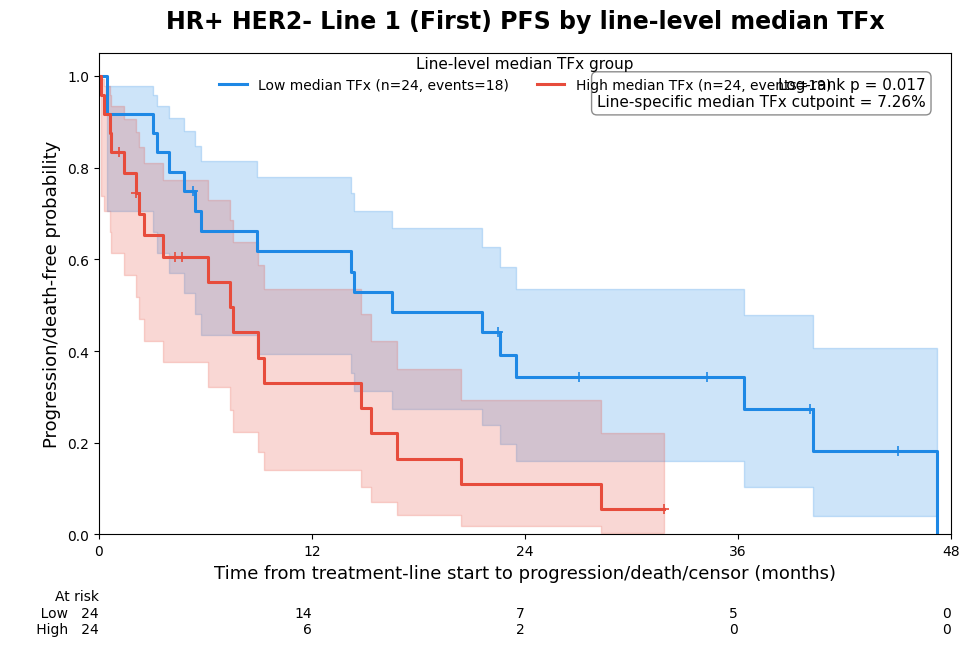

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_01_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_01_python_KM_median_TFx_PFS.pdf

Plotting treatment line 2
Line 2 (Second)
Rows: 43
Events: 33
Censored: 10
TFx cutpoint: 9.455
Low group: {'n': 21, 'events': 14, 'censored': 7, 'median_TFx': 6.893000000000001, 'median_PFS_months_observed': 4.271047227926078}
High group: {'n': 22, 'events': 19, 'censored': 3, 'median_TFx': 25.515, 'median_PFS_months_observed': 3.318275154004107}
Log-rank p-value: 0.11803162520691508


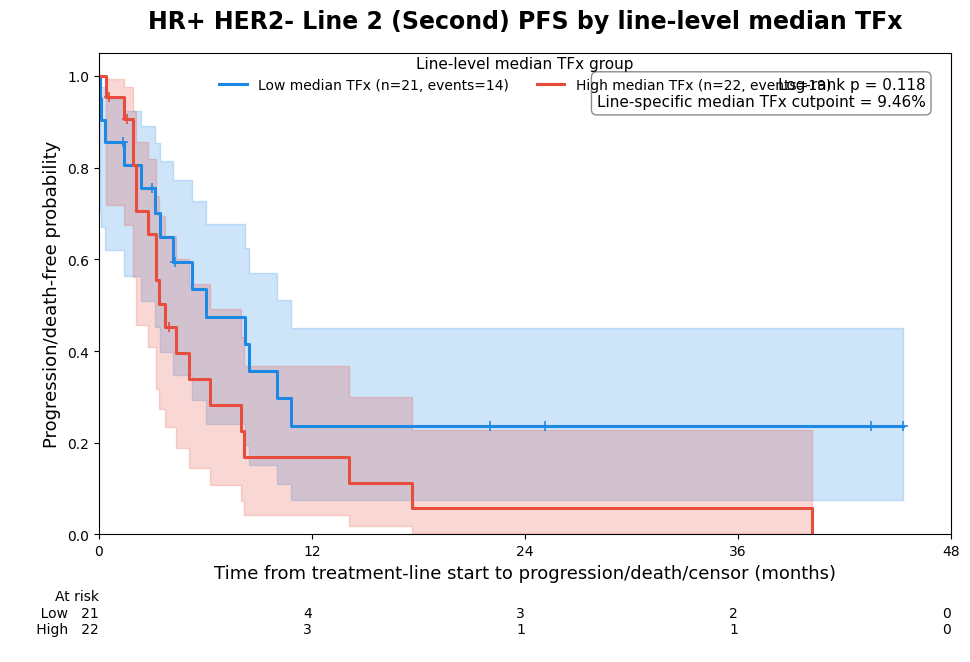

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_02_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_02_python_KM_median_TFx_PFS.pdf

Plotting treatment line 3
Line 3 (Third)
Rows: 38
Events: 30
Censored: 8
TFx cutpoint: 8.1845
Low group: {'n': 19, 'events': 15, 'censored': 4, 'median_TFx': 4.952, 'median_PFS_months_observed': 3.712525667351129}
High group: {'n': 19, 'events': 15, 'censored': 4, 'median_TFx': 19.27, 'median_PFS_months_observed': 3.646817248459959}
Log-rank p-value: 0.36987441750471994


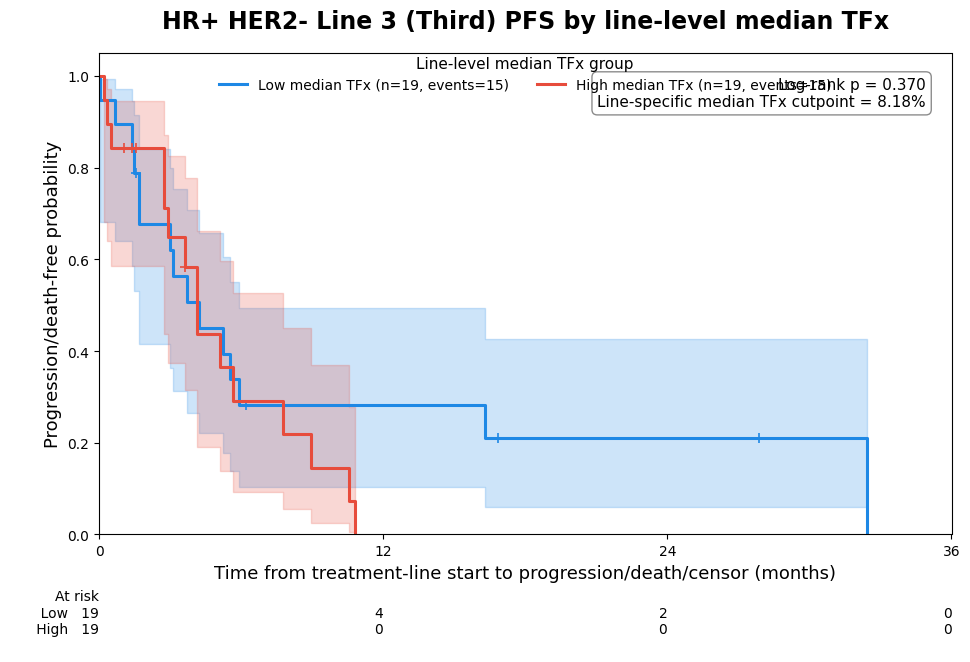

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_03_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_03_python_KM_median_TFx_PFS.pdf

Plotting treatment line 4
Line 4 (Fourth)
Rows: 32
Events: 28
Censored: 4
TFx cutpoint: 8.937000000000001
Low group: {'n': 16, 'events': 12, 'censored': 4, 'median_TFx': 4.9535, 'median_PFS_months_observed': 5.075975359342916}
High group: {'n': 16, 'events': 16, 'censored': 0, 'median_TFx': 23.34, 'median_PFS_months_observed': 3.351129363449692}
Log-rank p-value: 0.43591196018410083


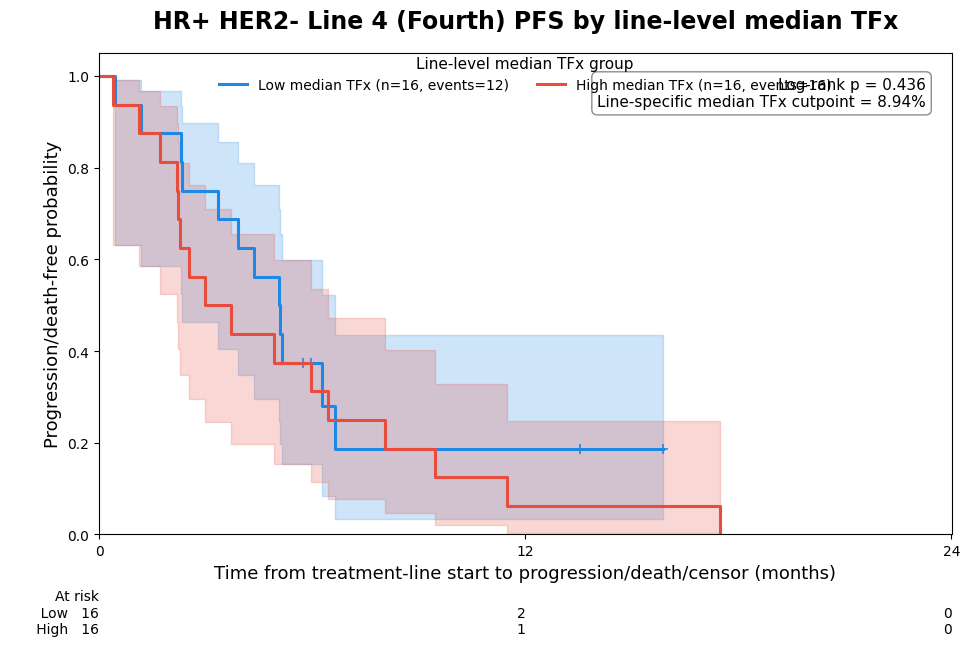

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_04_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_04_python_KM_median_TFx_PFS.pdf

Plotting treatment line 5
Line 5 (Fifth)
Rows: 31
Events: 25
Censored: 6
TFx cutpoint: 7.24
Low group: {'n': 15, 'events': 12, 'censored': 3, 'median_TFx': 5.545, 'median_PFS_months_observed': 3.3182751540041067}
High group: {'n': 16, 'events': 13, 'censored': 3, 'median_TFx': 23.33, 'median_PFS_months_observed': 2.9075975359342916}
Log-rank p-value: 0.6874664997420203


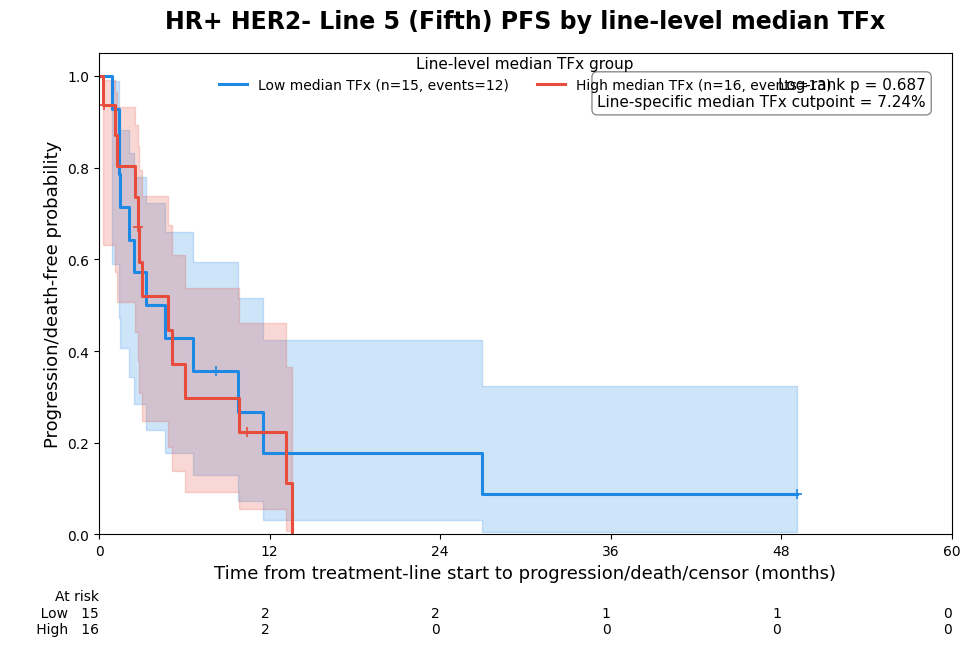

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_05_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_05_python_KM_median_TFx_PFS.pdf

========== Python KM summary ==========
 treatment_line_number line_label  status  n_patient_lines  n_events  n_censored  line_specific_TFx_cutpoint  low_n  low_events  low_censored  low_median_line_TFx  low_KM_median_PFS_months  high_n  high_events  high_censored  high_median_line_TFx  high_KM_median_PFS_months  logrank_p_value logrank_p_label
                     1      First Plotted               48        37          11                      7.2580     24          18             6               5.0360                 16.492813      24           19              5                14.960                   7.392197         0.017102     

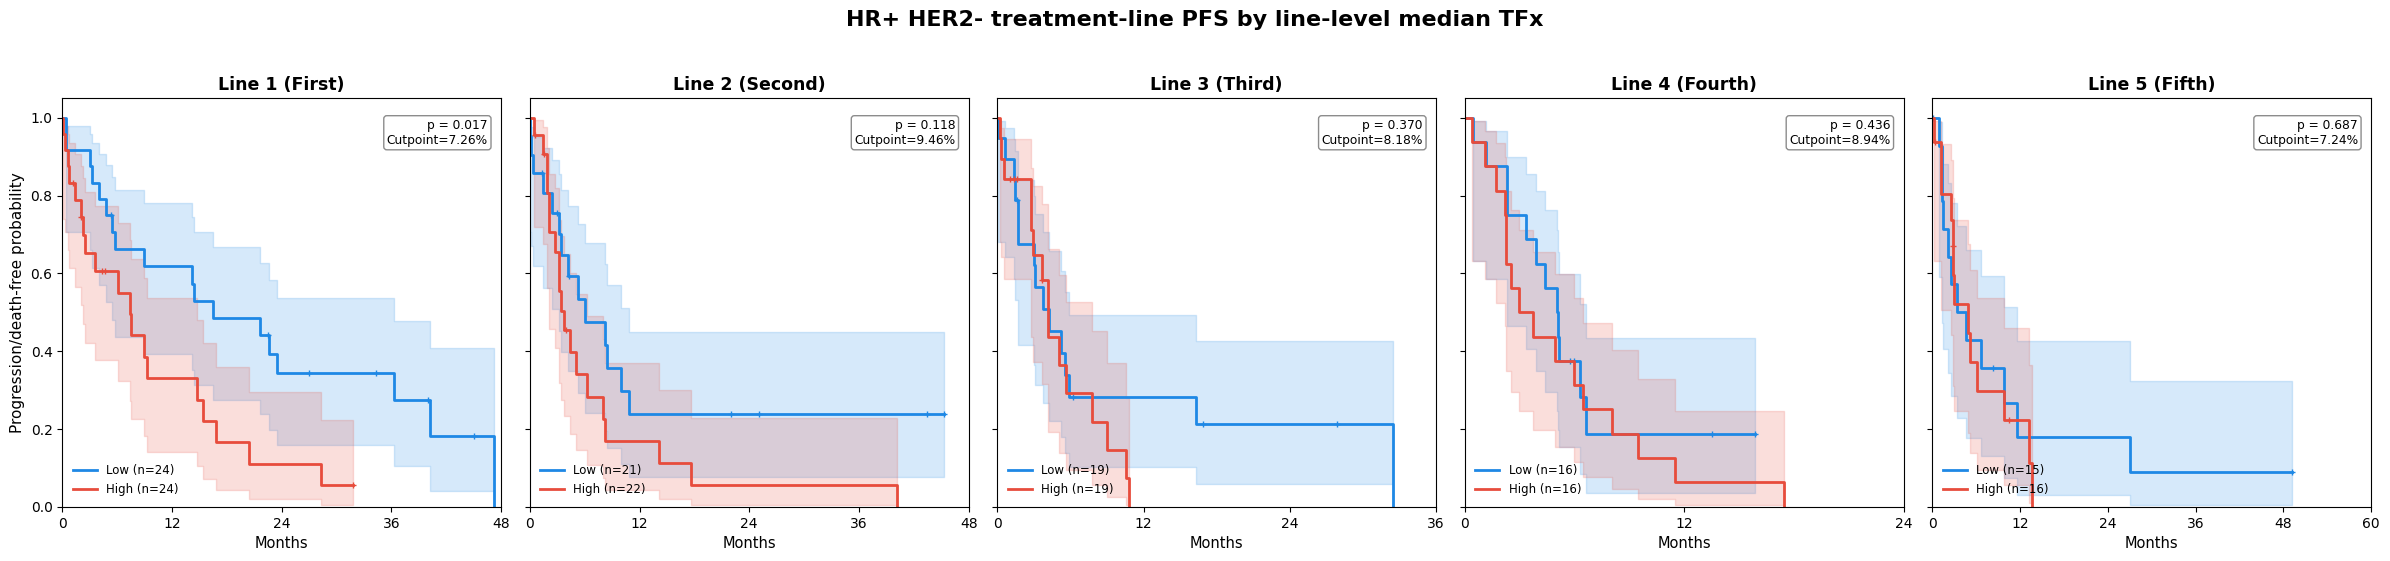


Saved combined preview:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach1/Python_KM_plots_LINES_1_5/HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.pdf


In [10]:
# ============================================================
# HR+ HER2- treatment-line PFS KM plots (Approach 1)
#
# Input:
#   HRpos_HER2neg_patient_line_median_TFx_PFS_LINES_1_3_for_R.csv
#
# Analysis:
#   - HR+ HER2- only
#   - Blood draws with TFx >= 3% were used upstream
#   - Multiple blood draws within same patient-treatment-line were summarized by median TFx
#   - Within each treatment line, Low/High TFx groups use line-specific median TFx cutpoint
#
# Outputs:
#   - Individual KM plots for Line 1, Line 2, Line 3
#   - Combined 3-panel preview plot
#   - Python KM summary CSV
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# If lifelines is not installed, install/activate it before running:
# !pip install lifelines

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.plotting import add_at_risk_counts


# ============================================================
# 1. Paths
# ============================================================

out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg"
)

input_file = out_dir / "Approach1" / "HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv"

plot_dir = out_dir / "Approach1"  / "Python_KM_plots_LINES_1_5"
plot_dir.mkdir(parents=True, exist_ok=True)

summary_out = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_summary.csv"

print("Input file:")
print(input_file)

print("\nPlot output directory:")
print(plot_dir)


# ============================================================
# 2. Settings
# ============================================================

LINES_TO_PLOT = [1, 2, 3, 4, 5]

time_col = "PFS_time_months"
event_col = "PFS_event"
group_col = "TFx_group_line_median"
line_col = "treatment_line_number"
line_label_col = "line_label"
cut_col = "line_specific_TFx_cutpoint"
tfx_col = "median_TFx_in_line"

low_group = "Low line-level median TFx"
high_group = "High line-level median TFx"

LOW_COLOR = "#1E88E5"
HIGH_COLOR = "#E74C3C"

DPI = 300


# ============================================================
# 3. Helper functions
# ============================================================

def format_p_value(p):
    if pd.isna(p):
        return "p = NA"
    elif p < 0.001:
        return "p < 0.001"
    else:
        return f"p = {p:.3f}"


def format_number(x, digits=2):
    if pd.isna(x):
        return "NA"
    return f"{x:.{digits}f}"


def format_median_survival(x):
    if x is None or pd.isna(x):
        return "NA"
    if np.isinf(x):
        return "Not reached"
    return f"{x:.2f}"


def clean_line_label(line_num, line_label):
    if pd.isna(line_label):
        return f"Line {int(line_num)}"
    return f"Line {int(line_num)} ({line_label})"


def prepare_line_df(df, line_num):
    line_df = df[df[line_col].eq(line_num)].copy()
    
    line_df[time_col] = pd.to_numeric(line_df[time_col], errors="coerce")
    line_df[event_col] = pd.to_numeric(line_df[event_col], errors="coerce")
    line_df[tfx_col] = pd.to_numeric(line_df[tfx_col], errors="coerce")
    
    line_df = line_df[
        line_df[time_col].notna()
        & line_df[event_col].notna()
        & line_df[group_col].notna()
        & (line_df[time_col] > 0)
    ].copy()
    
    line_df[event_col] = line_df[event_col].astype(int)
    
    line_df[group_col] = pd.Categorical(
        line_df[group_col],
        categories=[low_group, high_group],
        ordered=True
    )
    
    return line_df


def get_group_stats(line_df, group_name):
    g = line_df[line_df[group_col].eq(group_name)].copy()
    
    return {
        "n": g.shape[0],
        "events": int(g[event_col].sum()) if g.shape[0] > 0 else 0,
        "censored": int((g[event_col] == 0).sum()) if g.shape[0] > 0 else 0,
        "median_TFx": g[tfx_col].median() if g.shape[0] > 0 else np.nan,
        "median_PFS_months_observed": g[time_col].median() if g.shape[0] > 0 else np.nan,
    }


# ============================================================
# 4. Read data
# ============================================================

df = pd.read_csv(input_file)

print("\n========== Input summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())

# Basic cleanup
df[line_col] = pd.to_numeric(df[line_col], errors="coerce")
df[event_col] = pd.to_numeric(df[event_col], errors="coerce")
df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
df[tfx_col] = pd.to_numeric(df[tfx_col], errors="coerce")

df = df[df[line_col].isin(LINES_TO_PLOT)].copy()
df[line_col] = df[line_col].astype(int)

print("\nTreatment-line counts:")
print(df[line_col].value_counts().sort_index())

print("\nTFx groups by treatment line:")
print(pd.crosstab(df[line_col], df[group_col]))


# ============================================================
# 5. Individual KM plots by treatment line
# ============================================================

summary_rows = []

for line_num in LINES_TO_PLOT:
    
    print("\n============================================================")
    print(f"Plotting treatment line {line_num}")
    print("============================================================")
    
    line_df = prepare_line_df(df, line_num)
    
    if line_df.empty:
        print(f"Skipping Line {line_num}: no valid rows.")
        continue
    
    line_label = line_df[line_label_col].dropna().iloc[0] if line_label_col in line_df.columns and line_df[line_label_col].notna().any() else f"Line {line_num}"
    plot_line_label = clean_line_label(line_num, line_label)
    
    cutpoint = line_df[cut_col].dropna().iloc[0] if cut_col in line_df.columns and line_df[cut_col].notna().any() else line_df[tfx_col].median()
    
    low_df = line_df[line_df[group_col].eq(low_group)].copy()
    high_df = line_df[line_df[group_col].eq(high_group)].copy()
    
    low_stats = get_group_stats(line_df, low_group)
    high_stats = get_group_stats(line_df, high_group)
    
    print(f"{plot_line_label}")
    print("Rows:", line_df.shape[0])
    print("Events:", int(line_df[event_col].sum()))
    print("Censored:", int((line_df[event_col] == 0).sum()))
    print("TFx cutpoint:", cutpoint)
    print("Low group:", low_stats)
    print("High group:", high_stats)
    
    if low_df.shape[0] == 0 or high_df.shape[0] == 0:
        print(f"Skipping Line {line_num}: one TFx group is missing.")
        continue
    
    # ----------------------------
    # Fit KM curves
    # ----------------------------
    low_label = f"Low median TFx (n={low_stats['n']}, events={low_stats['events']})"
    high_label = f"High median TFx (n={high_stats['n']}, events={high_stats['events']})"
    
    kmf_low = KaplanMeierFitter(label=low_label)
    kmf_high = KaplanMeierFitter(label=high_label)
    
    kmf_low.fit(
        durations=low_df[time_col],
        event_observed=low_df[event_col]
    )
    
    kmf_high.fit(
        durations=high_df[time_col],
        event_observed=high_df[event_col]
    )
    
    # ----------------------------
    # Log-rank test
    # ----------------------------
    lr = logrank_test(
        low_df[time_col],
        high_df[time_col],
        event_observed_A=low_df[event_col],
        event_observed_B=high_df[event_col]
    )
    
    p_val = lr.p_value
    p_label = format_p_value(p_val)
    
    print("Log-rank p-value:", p_val)
    
    # ----------------------------
    # Plot settings
    # ----------------------------
    max_time = line_df[time_col].max()
    x_max = int(np.ceil(max_time / 12) * 12)
    x_max = max(x_max, 12)
    
    x_ticks = np.arange(0, x_max + 1, 12)
    
    annot_text = (
        f"Log-rank {p_label}\n"
        f"Line-specific median TFx cutpoint = {cutpoint:.2f}%"
    )
    
    # ----------------------------
    # Plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=(11, 8.3))
    
    kmf_low.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.22,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 7, "mew": 1.2},
        color=LOW_COLOR,
        linewidth=2.2
    )
    
    kmf_high.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.22,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 7, "mew": 1.2},
        color=HIGH_COLOR,
        linewidth=2.2
    )
    
    ax.set_title(
        f"HR+ HER2- {plot_line_label} PFS by line-level median TFx",
        fontsize=17,
        fontweight="bold",
        pad=18
    )
    
    ax.set_xlabel(
        "Time from treatment-line start to progression/death/censor (months)",
        fontsize=13
    )
    
    ax.set_ylabel(
        "Progression/death-free probability",
        fontsize=13
    )
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(x_ticks)
    
    ax.grid(False)
    
    ax.legend(
        title="Line-level median TFx group",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        frameon=False,
        fontsize=10,
        title_fontsize=11
    )
    
    ax.text(
        0.97,
        0.95,
        annot_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )
    
    # Single number-at-risk table only
    add_at_risk_counts(
        kmf_low,
        kmf_high,
        ax=ax,
        labels=["Low", "High"],
        rows_to_show=["At risk"],
        fontsize=10
    )
    
    plt.subplots_adjust(bottom=0.26, top=0.84)
    
    out_png = plot_dir / f"HRpos_HER2neg_Line_{line_num:02d}_python_KM_median_TFx_PFS.png"
    out_pdf = plot_dir / f"HRpos_HER2neg_Line_{line_num:02d}_python_KM_median_TFx_PFS.pdf"
    
    fig.savefig(out_png, dpi=DPI, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    
    plt.show()
    plt.close(fig)
    
    print("Saved:")
    print(out_png)
    print(out_pdf)
    
    # ----------------------------
    # Store summary
    # ----------------------------
    summary_rows.append(
        {
            "treatment_line_number": line_num,
            "line_label": line_label,
            "status": "Plotted",
            "n_patient_lines": line_df.shape[0],
            "n_events": int(line_df[event_col].sum()),
            "n_censored": int((line_df[event_col] == 0).sum()),
            "line_specific_TFx_cutpoint": cutpoint,
            
            "low_n": low_stats["n"],
            "low_events": low_stats["events"],
            "low_censored": low_stats["censored"],
            "low_median_line_TFx": low_stats["median_TFx"],
            "low_KM_median_PFS_months": kmf_low.median_survival_time_,
            
            "high_n": high_stats["n"],
            "high_events": high_stats["events"],
            "high_censored": high_stats["censored"],
            "high_median_line_TFx": high_stats["median_TFx"],
            "high_KM_median_PFS_months": kmf_high.median_survival_time_,
            
            "logrank_p_value": p_val,
            "logrank_p_label": p_label,
        }
    )


# ============================================================
# 6. Save KM summary
# ============================================================

km_summary = pd.DataFrame(summary_rows)

km_summary.to_csv(summary_out, index=False)

print("\n========== Python KM summary ==========")
print(km_summary.to_string(index=False))

print("\nSaved summary:")
print(summary_out)


# ============================================================
# 7. Combined 5-panel preview plot
#    Curve-only preview, no risk table
# ============================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(LINES_TO_PLOT),
    figsize=(24, 5.4),
    sharey=True
)

for ax, line_num in zip(axes, LINES_TO_PLOT):
    
    line_df = prepare_line_df(df, line_num)
    
    if line_df.empty:
        ax.set_title(f"Line {line_num}: no data")
        ax.axis("off")
        continue
    
    line_label = (
        line_df[line_label_col].dropna().iloc[0]
        if line_label_col in line_df.columns and line_df[line_label_col].notna().any()
        else f"Line {line_num}"
    )
    
    plot_line_label = clean_line_label(line_num, line_label)
    
    cutpoint = (
        line_df[cut_col].dropna().iloc[0]
        if cut_col in line_df.columns and line_df[cut_col].notna().any()
        else line_df[tfx_col].median()
    )
    
    low_df = line_df[line_df[group_col].eq(low_group)].copy()
    high_df = line_df[line_df[group_col].eq(high_group)].copy()
    
    low_stats = get_group_stats(line_df, low_group)
    high_stats = get_group_stats(line_df, high_group)
    
    if low_df.shape[0] == 0 or high_df.shape[0] == 0:
        ax.set_title(f"{plot_line_label}: missing group")
        ax.axis("off")
        continue
    
    kmf_low = KaplanMeierFitter(label=f"Low (n={low_stats['n']})")
    kmf_high = KaplanMeierFitter(label=f"High (n={high_stats['n']})")
    
    kmf_low.fit(
        low_df[time_col],
        event_observed=low_df[event_col]
    )
    
    kmf_high.fit(
        high_df[time_col],
        event_observed=high_df[event_col]
    )
    
    lr = logrank_test(
        low_df[time_col],
        high_df[time_col],
        event_observed_A=low_df[event_col],
        event_observed_B=high_df[event_col]
    )
    
    p_label = format_p_value(lr.p_value)
    
    kmf_low.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.18,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 5},
        color=LOW_COLOR,
        linewidth=2
    )
    
    kmf_high.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.18,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 5},
        color=HIGH_COLOR,
        linewidth=2
    )
    
    max_time = line_df[time_col].max()
    x_max = int(np.ceil(max_time / 12) * 12)
    x_max = max(x_max, 12)
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(np.arange(0, x_max + 1, 12))
    
    ax.set_title(
        plot_line_label,
        fontsize=12.5,
        fontweight="bold"
    )
    
    ax.set_xlabel("Months", fontsize=10.5)
    
    if line_num == LINES_TO_PLOT[0]:
        ax.set_ylabel("Progression/death-free probability", fontsize=11)
    else:
        ax.set_ylabel("")
    
    ax.grid(False)
    
    ax.text(
        0.97,
        0.95,
        f"{p_label}\nCutpoint={cutpoint:.2f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.8,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )
    
    ax.legend(
        loc="lower left",
        frameon=False,
        fontsize=8.5
    )

fig.suptitle(
    "HR+ HER2- treatment-line PFS by line-level median TFx",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

combined_png = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.png"
combined_pdf = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.pdf"

fig.savefig(combined_png, dpi=DPI, bbox_inches="tight")
fig.savefig(combined_pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nSaved combined preview:")
print(combined_png)
print(combined_pdf)

In [9]:
# ============================================================
# HR+ HER2- treatment-line-level PFS (Approach 2)
#
# logic:
#
#   1. Define the analytic TFx cohort first:
#        patients with at least one cfDNA Blood_Draw row with non-missing TFx.
#
#   2. Receptor status is derived ONLY from rows where:
#        Category == "First_Primary"
#      and only among patients in the TFx cohort.
#
#   3. HR+ HER2- definition:
#        HR+   = ER positive OR PR positive
#        HER2- = HER2 negative
#
#   4. Restrict analysis to HR+ HER2- patients.
#
#   5. Blood-draw eligibility:
#        include only individual cfDNA blood draws with TFx >= 3%.
#
#   6. Assign eligible blood draws to metastatic treatment lines using:
#        line_start_day ≤ blood_draw_day ≤ line_end_day
#
#   7. For each patient-treatment-line:
#        If multiple draws in same line: median_TFx_in_line = median(TFx values
#
#   8. Calculate treatment-line PFS:
#        time from treatment-line start to progression / death / censor.
#
#   9. Within each treatment line separately:
#        calculate the line-specific median of median_TFx_in_line,
#        then classify patient-lines as:
#          Low line-level median TFx
#          High line-level median TFx
#
#  10. Export clean patient-treatment-line CSV files for KM plotting:
#        Lines 1-3 are primary/exploratory-ready.
#        Lines 4-5 may also be plotted as exploratory because n > 20,
#        but should be interpreted cautiously, especially Line 4
#        because of very few censored observations.
#
# Output directory:
#   /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re

# ============================================================
# 1. Paths and settings
# ============================================================

survival_dir = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival")

clinical_file = survival_dir / "AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv"

out_dir = survival_dir / "PFS_Analysis_HRpos_Herneg" / "Approach2" 
out_dir.mkdir(parents=True, exist_ok=True)

# Main setting requested:
# TFx for each patient-treatment-line = median TFx of eligible blood draws assigned to that line
TFX_SUMMARY_METHOD = "median"

# Blood-draw-level TFx eligibility threshold
# IMPORTANT:
# The filter is applied to individual blood draws BEFORE calculating patient-line median TFx.
MIN_BLOOD_DRAW_TFX_PERCENT = 3.0

# Strict assignment:
# blood draw is assigned if:
#   line_start_day <= blood_draw_day <= assignment_end_day
#
# If later you want baseline draws a few days before treatment start included,
# change this to 7 or 14.
PRE_LINE_WINDOW_DAYS = 0

# Main treatment lines to export separately for R plotting
LINES_TO_ANALYZE = [1, 2, 3]

DAYS_PER_MONTH = 365.25 / 12

print("Input clinical file:")
print(clinical_file)

print("\nOutput directory:")
print(out_dir)

print("\nSettings:")
print("TFX_SUMMARY_METHOD:", TFX_SUMMARY_METHOD)
print("MIN_BLOOD_DRAW_TFX_PERCENT:", MIN_BLOOD_DRAW_TFX_PERCENT)
print("PRE_LINE_WINDOW_DAYS:", PRE_LINE_WINDOW_DAYS)
print("LINES_TO_ANALYZE:", LINES_TO_ANALYZE)

# ============================================================
# 2. Helper functions
# ============================================================

def clean_text(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "":
        return np.nan
    return re.sub(r"\s+", " ", s)


def clean_id(x):
    return clean_text(x)


def normalize_er_pr(x):
    """
    ER/PR normalization.
    Positive if clearly positive.
    Negative if clearly negative.
    Ambiguous/equivocal/unknown set to missing.
    """
    s = clean_text(x)
    if pd.isna(s):
        return np.nan

    u = s.upper()

    if u in {
        "NA", "N/A", "UNKNOWN", "MISSING",
        "NOT AVAILABLE", "NOT ASSESSED", "NONE"
    }:
        return np.nan

    if (
        "POSITIVE" in u
        or re.search(r"\bPOS\b", u)
        or u in {"P", "+", "1", "YES"}
    ):
        return "Positive"

    if (
        "NEGATIVE" in u
        or re.search(r"\bNEG\b", u)
        or u in {"N", "-", "0", "NO"}
    ):
        return "Negative"

    if re.search(r"EQUIVOCAL|BORDERLINE|INDETERMINATE|INDETERMINED", u):
        return np.nan

    return np.nan


def normalize_her2(x):
    """
    HER2 normalization.
    Important:
      0 / 1+ = Negative
      2+ = missing/equivocal
      3+ / amplified = Positive
    """
    s = clean_text(x)
    if pd.isna(s):
        return np.nan

    u = s.upper()

    if u in {
        "NA", "N/A", "UNKNOWN", "MISSING",
        "NOT AVAILABLE", "NOT ASSESSED", "NONE"
    }:
        return np.nan

    # Negative calls first, before generic AMPLIFIED check
    if re.search(r"NOT AMPLIFIED|NON-AMPLIFIED|NON AMPLIFIED|UNAMPLIFIED", u):
        return "Negative"

    if (
        "NEGATIVE" in u
        or re.search(r"\bNEG\b", u)
        or u in {"N", "-", "0", "0+", "1+", "NO"}
    ):
        return "Negative"

    if re.search(r"\bIHC\s*0\b", u) or re.search(r"\bIHC\s*1\+\b", u):
        return "Negative"

    if (
        re.search(r"EQUIVOCAL|BORDERLINE|INDETERMINATE|INDETERMINED", u)
        or u in {"2+", "IHC 2+"}
        or re.search(r"\bIHC\s*2\+\b", u)
    ):
        return np.nan

    if (
        "AMPLIFIED" in u
        or "POSITIVE" in u
        or re.search(r"\bPOS\b", u)
        or u in {"P", "+", "3+", "YES"}
        or re.search(r"\bIHC\s*3\+\b", u)
    ):
        return "Positive"

    return np.nan


def most_common_nonmissing(x):
    x = x.dropna().astype(str)
    x = x[x != ""]
    if len(x) == 0:
        return np.nan
    return x.value_counts().index[0]


def collapse_unique_nonmissing(x):
    vals = pd.unique(x.dropna().astype(str))
    vals = [v for v in vals if v != ""]
    if len(vals) == 0:
        return np.nan
    return "; ".join(vals)


line_map = {
    "FIRST": 1, "1": 1, "1ST": 1,
    "SECOND": 2, "2": 2, "2ND": 2,
    "THIRD": 3, "3": 3, "3RD": 3,
    "FOURTH": 4, "4": 4, "4TH": 4,
    "FIFTH": 5, "5": 5, "5TH": 5,
    "SIXTH": 6, "6": 6, "6TH": 6,
    "SEVENTH": 7, "7": 7, "7TH": 7,
    "EIGHTH": 8, "8": 8, "8TH": 8,
    "NINTH": 9, "9": 9, "9TH": 9,
    "TENTH": 10, "10": 10, "10TH": 10,
    "ELEVENTH": 11, "11": 11, "11TH": 11,
    "TWELFTH": 12, "12": 12, "12TH": 12,
    "THIRTEENTH": 13, "13": 13, "13TH": 13,
    "FOURTEENTH": 14, "14": 14, "14TH": 14,
}

line_label_map = {
    1: "First",
    2: "Second",
    3: "Third",
    4: "Fourth",
    5: "Fifth",
    6: "Sixth",
    7: "Seventh",
    8: "Eighth",
    9: "Ninth",
    10: "Tenth",
    11: "Eleventh",
    12: "Twelfth",
    13: "Thirteenth",
    14: "Fourteenth",
}


def line_to_number(x):
    s = clean_text(x)
    if pd.isna(s):
        return np.nan
    return line_map.get(s.upper(), np.nan)


def number_to_line_label(x):
    if pd.isna(x):
        return np.nan
    x = int(x)
    return line_label_map.get(x, f"Line {x}")


def safe_name(x):
    x = str(x)
    x = x.replace("+", "pos")
    x = x.replace("-", "neg")
    x = re.sub(r"\s+", "_", x)
    x = re.sub(r"[^A-Za-z0-9_]", "", x)
    return x


def is_progression_row(row):
    """
    Progression event logic using available treatment columns.
    """
    treatment_response = clean_text(row.get("Treatment_Response"))
    progression = clean_text(row.get("Progression"))
    reason = clean_text(row.get("Reason_Tx_Ended"))

    treatment_response = "" if pd.isna(treatment_response) else treatment_response.upper()
    progression = "" if pd.isna(progression) else progression.upper()
    reason = "" if pd.isna(reason) else reason.upper()

    return (
        treatment_response == "PROGRESSION"
        or progression.startswith("YES")
        or "PROGRESSION" in reason
    )


# ============================================================
# 3. Load clinical file
# ============================================================

df = pd.read_csv(clinical_file, low_memory=False)

print("\n========== Input file summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())

# Required core columns
required_core_cols = [
    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "Met_Therapy_Line",
    "EndTrt_Days_From_Primary_Diagnosis",
    "ER_Status",
    "PR_Status",
    "HER2_Status",
]

missing_core_cols = [c for c in required_core_cols if c not in df.columns]
if missing_core_cols:
    raise ValueError(f"Missing required columns: {missing_core_cols}")

# If TFx column is named differently, detect and standardize
if "TFx" not in df.columns:
    possible_tfx_cols = [
        "Tumor_Fraction_percent_from_CNV_annotation",
        "Tumor_Fraction_percent",
        "TFx_percent",
        "tumor_fraction",
    ]
    found_tfx_cols = [c for c in possible_tfx_cols if c in df.columns]
    if len(found_tfx_cols) == 0:
        raise ValueError(
            "No TFx column found. Tried TFx and possible alternatives: "
            + ", ".join(possible_tfx_cols)
        )
    df["TFx"] = df[found_tfx_cols[0]]
    print(f"\nCreated TFx column from: {found_tfx_cols[0]}")

# Optional columns that may or may not exist
optional_numeric_cols = [
    "Line_Start_Days_From_Primary_Diagnosis",
    "Progression_Free_Survival",
]

for col in optional_numeric_cols:
    if col not in df.columns:
        df[col] = np.nan
        print(f"Created missing optional column as NA: {col}")

# Numeric cleanup
numeric_cols = [
    "Days_From_Primary_Diagnosis",
    "EndTrt_Days_From_Primary_Diagnosis",
    "Line_Start_Days_From_Primary_Diagnosis",
    "TFx",
    "Progression_Free_Survival",
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean patient ID
if "patient_id_clean" not in df.columns:
    df["patient_id_clean"] = df["patient_id"].map(clean_id)
else:
    df["patient_id_clean"] = df["patient_id_clean"].map(clean_id)

print("\nUnique patients in file:", df["patient_id_clean"].nunique())


# ============================================================
# 4. Define TFx patient cohort (at least one cfDNA blood draw), 
# then derive receptor subtype from First_Primary rows only
# ============================================================

tfx_patient_rows = df[
    df["Category"].astype(str).str.strip().eq("Blood_Draw")
    & df["TFx"].notna()
    & df["patient_id_clean"].notna()
].copy()

tfx_patient_ids = set(tfx_patient_rows["patient_id_clean"].dropna().unique())

print("\n========== TFx patient cohort ==========")
print("Blood draw rows with non-missing TFx:", tfx_patient_rows.shape[0])
print("Unique patients with at least one TFx blood draw:", len(tfx_patient_ids))

tfx_patient_cohort_file = out_dir / "AURORA_patients_with_any_TFx_blood_draw.csv"

(
    tfx_patient_rows[["patient_id_clean"]]
    .drop_duplicates()
    .sort_values("patient_id_clean")
    .to_csv(tfx_patient_cohort_file, index=False)
)

print("Saved TFx patient cohort:")
print(tfx_patient_cohort_file)

# ------------------------------------------------------------
# Receptor status source:
# Category == First_Primary only
# but restricted to patients with at least one TFx blood draw.
# ------------------------------------------------------------

first_primary_all = df[
    df["Category"].astype(str).str.strip().eq("First_Primary")
].copy()

first_primary = first_primary_all[
    first_primary_all["patient_id_clean"].isin(tfx_patient_ids)
].copy()

print("\n========== First_Primary receptor source rows ==========")
print("All First_Primary rows:", first_primary_all.shape[0])
print("Unique patients in all First_Primary rows:", first_primary_all["patient_id_clean"].nunique())

print("\nFirst_Primary rows after restricting to patients with TFx:")
print("Rows:", first_primary.shape[0])
print("Unique patients:", first_primary["patient_id_clean"].nunique())

# Patients in First_Primary but not in TFx cohort
first_primary_no_tfx = first_primary_all[
    ~first_primary_all["patient_id_clean"].isin(tfx_patient_ids)
].copy()

first_primary_no_tfx_file = out_dir / "First_Primary_patients_excluded_no_TFx_blood_draw.csv"
first_primary_no_tfx.to_csv(first_primary_no_tfx_file, index=False)

print("\nFirst_Primary patients excluded because no TFx blood draw:")
print(first_primary_no_tfx["patient_id_clean"].nunique())
print("Saved excluded First_Primary no-TFx patients:")
print(first_primary_no_tfx_file)

# ------------------------------------------------------------
# Normalize receptors
# ------------------------------------------------------------

first_primary["ER_clean_row"] = first_primary["ER_Status"].map(normalize_er_pr)
first_primary["PR_clean_row"] = first_primary["PR_Status"].map(normalize_er_pr)
first_primary["HER2_clean_row"] = first_primary["HER2_Status"].map(normalize_her2)

receptor_by_patient = (
    first_primary
    .groupby("patient_id_clean", dropna=True)
    .agg(
        ER_clean=("ER_clean_row", most_common_nonmissing),
        PR_clean=("PR_clean_row", most_common_nonmissing),
        HER2_clean=("HER2_clean_row", most_common_nonmissing),

        ER_Status_raw_values=("ER_Status", collapse_unique_nonmissing),
        PR_Status_raw_values=("PR_Status", collapse_unique_nonmissing),
        HER2_Status_raw_values=("HER2_Status", collapse_unique_nonmissing),

        n_first_primary_rows=("Category", "count"),
    )
    .reset_index()
)

# ------------------------------------------------------------
# HR and receptor subtype logic
# ------------------------------------------------------------

# HR+ means ER positive OR PR positive
# HR- means ER negative AND PR negative
receptor_by_patient["HR_status"] = np.select(
    [
        receptor_by_patient["ER_clean"].eq("Positive")
        | receptor_by_patient["PR_clean"].eq("Positive"),

        receptor_by_patient["ER_clean"].eq("Negative")
        & receptor_by_patient["PR_clean"].eq("Negative"),
    ],
    ["HR+", "HR-"],
    default=None
)

# Molecular subtype
receptor_by_patient["receptor_subtype"] = np.select(
    [
        receptor_by_patient["HR_status"].eq("HR+")
        & receptor_by_patient["HER2_clean"].eq("Negative"),

        receptor_by_patient["HR_status"].eq("HR+")
        & receptor_by_patient["HER2_clean"].eq("Positive"),

        receptor_by_patient["HR_status"].eq("HR-")
        & receptor_by_patient["HER2_clean"].eq("Negative"),

        receptor_by_patient["HR_status"].eq("HR-")
        & receptor_by_patient["HER2_clean"].eq("Positive"),
    ],
    [
        "HR+ HER2-",
        "HR+ HER2+",
        "HR- HER2-",
        "HR- HER2+",
    ],
    default=None
)

# ------------------------------------------------------------
# Save and print receptor subtype counts
# ------------------------------------------------------------

#receptor_crosswalk_file = out_dir / "TFx_patients_receptor_crosswalk_First_Primary_only.csv"
# receptor_by_patient.to_csv(receptor_crosswalk_file, index=False)

print("\n========== Receptor subtype counts among patients with TFx ==========")
print(receptor_by_patient["receptor_subtype"].value_counts(dropna=False))

print("\n========== HR status counts among patients with TFx ==========")
print(receptor_by_patient["HR_status"].value_counts(dropna=False))

print("\n========== Clean receptor status counts among patients with TFx ==========")
print("\nER:")
print(receptor_by_patient["ER_clean"].value_counts(dropna=False))

print("\nPR:")
print(receptor_by_patient["PR_clean"].value_counts(dropna=False))

print("\nHER2:")
print(receptor_by_patient["HER2_clean"].value_counts(dropna=False))

receptor_subtype_counts = (
    receptor_by_patient["receptor_subtype"]
    .value_counts(dropna=False)
    .rename_axis("receptor_subtype")
    .reset_index(name="n_patients")
)

# receptor_subtype_counts_file = out_dir / "TFx_patients_receptor_subtype_counts_First_Primary_only.csv"
# receptor_subtype_counts.to_csv(receptor_subtype_counts_file, index=False)

print("\nSaved receptor crosswalk:")
print(receptor_crosswalk_file)

print("\nSaved receptor subtype counts:")
print(receptor_subtype_counts_file)

# ------------------------------------------------------------
# Final HR+ HER2- patient set for treatment-line PFS analysis
# ------------------------------------------------------------

hrpos_her2neg_patients = set(
    receptor_by_patient.loc[
        receptor_by_patient["receptor_subtype"].eq("HR+ HER2-"),
        "patient_id_clean"
    ]
)

print("\nHR+ HER2- patients among patients with TFx:", len(hrpos_her2neg_patients))

# ============================================================
# 5. Patient OS / last follow-up information
# ============================================================

os_rows = df[df["Category"].eq("Overall_Survival_days")].copy()

patient_os = (
    os_rows
    .groupby("patient_id_clean", dropna=True)
    .agg(
        os_day=("Days_From_Primary_Diagnosis", "max"),
        os_event_raw=("OS_event", most_common_nonmissing),
    )
    .reset_index()
)

patient_os["death_day"] = np.where(
    patient_os["os_event_raw"].astype(str).str.upper().eq("DEAD"),
    patient_os["os_day"],
    np.nan
)

patient_last_day = (
    df
    .groupby("patient_id_clean", dropna=True)
    .agg(
        last_known_day=("Days_From_Primary_Diagnosis", "max"),
        max_endtrt_day=("EndTrt_Days_From_Primary_Diagnosis", "max"),
    )
    .reset_index()
)

patient_last_day["last_followup_day"] = patient_last_day[
    ["last_known_day", "max_endtrt_day"]
].max(axis=1, skipna=True)

patient_followup = patient_os.merge(
    patient_last_day[["patient_id_clean", "last_followup_day"]],
    on="patient_id_clean",
    how="outer"
)

patient_followup_file = out_dir / "HRpos_HER2neg_patient_followup_days.csv"
patient_followup.to_csv(patient_followup_file, index=False)

print("\nSaved patient follow-up table:")
print(patient_followup_file)

# ============================================================
# 6. Build treatment-line table for HR+ HER2- patients
# ============================================================

therapy_rows = df[df["Met_Therapy_Line"].notna()].copy()

therapy_rows["treatment_line_number"] = therapy_rows["Met_Therapy_Line"].map(line_to_number)

therapy_rows = therapy_rows[
    therapy_rows["patient_id_clean"].isin(hrpos_her2neg_patients)
    & therapy_rows["treatment_line_number"].notna()
].copy()

therapy_rows["progression_flag"] = therapy_rows.apply(is_progression_row, axis=1)

therapy_rows["line_start_candidate"] = therapy_rows[
    "Line_Start_Days_From_Primary_Diagnosis"
].combine_first(
    therapy_rows["Days_From_Primary_Diagnosis"]
)

print("\n========== HR+ HER2- treatment rows ==========")
print("Rows:", therapy_rows.shape[0])
print("Patients:", therapy_rows["patient_id_clean"].nunique())
print("Treatment-line values:")
print(therapy_rows["Met_Therapy_Line"].value_counts(dropna=False).sort_index())

therapy_rows_file = out_dir / "HRpos_HER2neg_therapy_rows.csv"
therapy_rows.to_csv(therapy_rows_file, index=False)

print("\nSaved HR+ HER2- therapy rows:")
print(therapy_rows_file)

treatment_lines = (
    therapy_rows
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        Met_Therapy_Line=("Met_Therapy_Line", most_common_nonmissing),
        line_start_day=("line_start_candidate", "min"),
        line_end_day=("EndTrt_Days_From_Primary_Diagnosis", "max"),
        n_regimen_rows=("Regimen", "count"),
        regimen_list=("Regimen", collapse_unique_nonmissing),
        existing_PFS_min=("Progression_Free_Survival", "min"),
        existing_PFS_max=("Progression_Free_Survival", "max"),
    )
    .reset_index()
    .sort_values(["patient_id_clean", "treatment_line_number"])
)

progression_days = (
    therapy_rows[
        therapy_rows["progression_flag"]
        & therapy_rows["EndTrt_Days_From_Primary_Diagnosis"].notna()
    ]
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        progression_day=("EndTrt_Days_From_Primary_Diagnosis", "min")
    )
    .reset_index()
)

treatment_lines = treatment_lines.merge(
    progression_days,
    on=["patient_id_clean", "treatment_line_number"],
    how="left"
)

treatment_lines = treatment_lines.merge(
    patient_followup,
    on="patient_id_clean",
    how="left"
)

treatment_lines["next_line_start_day"] = (
    treatment_lines
    .groupby("patient_id_clean")["line_start_day"]
    .shift(-1)
)

treatment_lines["line_label"] = treatment_lines["treatment_line_number"].map(
    number_to_line_label
)

# ------------------------------------------------------------
# Assignment interval:
#   Start = treatment-line start
#   End   = EndTrt_Days_From_Primary_Diagnosis if available
#           otherwise next line start
#           otherwise last follow-up
# ------------------------------------------------------------

treatment_lines["assignment_end_day"] = treatment_lines["line_end_day"]

mask = (
    treatment_lines["assignment_end_day"].isna()
    & treatment_lines["next_line_start_day"].notna()
)
treatment_lines.loc[mask, "assignment_end_day"] = treatment_lines.loc[
    mask, "next_line_start_day"
]

mask = treatment_lines["assignment_end_day"].isna()
treatment_lines.loc[mask, "assignment_end_day"] = treatment_lines.loc[
    mask, "last_followup_day"
]

# ------------------------------------------------------------
# Treatment-line PFS:
# Event = progression within line interval OR death within line interval
# Censor = assignment_end_day if no progression/death in that line window
# ------------------------------------------------------------

treatment_lines["progression_candidate_day"] = np.where(
    treatment_lines["progression_day"].notna()
    & (treatment_lines["progression_day"] >= treatment_lines["line_start_day"])
    & (treatment_lines["progression_day"] <= treatment_lines["assignment_end_day"]),
    treatment_lines["progression_day"],
    np.nan
)

treatment_lines["death_candidate_day"] = np.where(
    treatment_lines["death_day"].notna()
    & (treatment_lines["death_day"] >= treatment_lines["line_start_day"])
    & (treatment_lines["death_day"] <= treatment_lines["assignment_end_day"]),
    treatment_lines["death_day"],
    np.nan
)

treatment_lines["event_day"] = treatment_lines[
    ["progression_candidate_day", "death_candidate_day"]
].min(axis=1, skipna=True)

treatment_lines["PFS_event"] = np.where(
    treatment_lines["event_day"].notna(),
    1,
    0
)

treatment_lines["censor_day"] = np.where(
    treatment_lines["PFS_event"].eq(1),
    np.nan,
    treatment_lines["assignment_end_day"]
)

treatment_lines["PFS_end_day"] = treatment_lines["event_day"].combine_first(
    treatment_lines["censor_day"]
)

treatment_lines["PFS_event_type"] = np.where(
    treatment_lines["PFS_event"].eq(0),
    "Censored",
    np.where(
        treatment_lines["progression_candidate_day"].notna()
        & treatment_lines["death_candidate_day"].notna()
        & np.isclose(
            treatment_lines["progression_candidate_day"],
            treatment_lines["death_candidate_day"],
            equal_nan=False
        ),
        "Progression+Death",
        np.where(
            treatment_lines["progression_candidate_day"].notna(),
            "Progression",
            "Death"
        )
    )
)

treatment_lines["PFS_time_days"] = (
    treatment_lines["PFS_end_day"] - treatment_lines["line_start_day"]
)

treatment_lines["PFS_time_months"] = (
    treatment_lines["PFS_time_days"] / DAYS_PER_MONTH
)

treatment_lines["PFS_QC_flag_new"] = np.where(
    treatment_lines["PFS_time_days"].isna(),
    "Missing PFS end/start day",
    np.where(
        treatment_lines["PFS_time_days"] <= 0,
        "PFS time <= 0",
        "OK"
    )
)

treatment_lines_file = out_dir / "HRpos_HER2neg_treatment_lines_PFS_all.csv"
treatment_lines.to_csv(treatment_lines_file, index=False)

print("\n========== Treatment-line PFS QC ==========")
print(treatment_lines["PFS_QC_flag_new"].value_counts(dropna=False))

print("\nTreatment-line counts:")
print(treatment_lines["treatment_line_number"].value_counts().sort_index())

print("\nSaved treatment-line table:")
print(treatment_lines_file)

# ============================================================
# 7. Assign eligible blood draws to treatment lines
#    Eligibility: individual blood draw TFx >= 3%
# ============================================================

all_hrpos_her2neg_blood_draws = df[
    df["Category"].eq("Blood_Draw")
    & df["TFx"].notna()
    & df["patient_id_clean"].isin(hrpos_her2neg_patients)
].copy()

all_hrpos_her2neg_blood_draws["blood_draw_day"] = all_hrpos_her2neg_blood_draws[
    "Days_From_Primary_Diagnosis"
]

all_hrpos_her2neg_blood_draws = all_hrpos_her2neg_blood_draws[
    [
        "patient_id_clean",
        "Barcode",
        "blood_draw_day",
        "TFx",
    ]
].rename(
    columns={
        "Barcode": "blood_draw_barcode"
    }
)

all_blood_draws_file = out_dir / "HRpos_HER2neg_all_blood_draws_with_TFx_before_TFx3_filter.csv"
all_hrpos_her2neg_blood_draws.to_csv(all_blood_draws_file, index=False)

# ------------------------------------------------------------
# Blood-draw-level TFx filter
# ------------------------------------------------------------

eligible_blood_draws = all_hrpos_her2neg_blood_draws[
    all_hrpos_her2neg_blood_draws["TFx"] >= MIN_BLOOD_DRAW_TFX_PERCENT
].copy()

excluded_low_tfx_blood_draws = all_hrpos_her2neg_blood_draws[
    all_hrpos_her2neg_blood_draws["TFx"] < MIN_BLOOD_DRAW_TFX_PERCENT
].copy()

eligible_blood_draws_file = out_dir / "HRpos_HER2neg_eligible_blood_draws_TFx_ge_3percent.csv"
excluded_low_tfx_blood_draws_file = out_dir / "HRpos_HER2neg_excluded_blood_draws_TFx_below_3percent.csv"

eligible_blood_draws.to_csv(eligible_blood_draws_file, index=False)
excluded_low_tfx_blood_draws.to_csv(excluded_low_tfx_blood_draws_file, index=False)

print("\n========== HR+ HER2- blood draw TFx filter ==========")
print("All HR+ HER2- blood draws with TFx:", all_hrpos_her2neg_blood_draws.shape[0])
print("Eligible blood draws with TFx >= 3%:", eligible_blood_draws.shape[0])
print("Excluded blood draws with TFx < 3%:", excluded_low_tfx_blood_draws.shape[0])
print("Patients with any blood draw:", all_hrpos_her2neg_blood_draws["patient_id_clean"].nunique())
print("Patients with eligible TFx >= 3% blood draw:", eligible_blood_draws["patient_id_clean"].nunique())

print("\nSaved all blood draws before TFx filter:")
print(all_blood_draws_file)

print("\nSaved eligible blood draws:")
print(eligible_blood_draws_file)

print("\nSaved excluded low-TFx blood draws:")
print(excluded_low_tfx_blood_draws_file)

# From here onward, only eligible blood draws are assigned to treatment lines
blood_draws = eligible_blood_draws.copy()

# Merge eligible blood draws to all treatment lines from same patient
draw_line_candidates = blood_draws.merge(
    treatment_lines[
        [
            "patient_id_clean",
            "treatment_line_number",
            "line_label",
            "line_start_day",
            "line_end_day",
            "assignment_end_day",
            "next_line_start_day",
        ]
    ],
    on="patient_id_clean",
    how="left"
)

# Keep draws falling inside treatment-line interval
draw_line_candidates = draw_line_candidates[
    (
        draw_line_candidates["blood_draw_day"]
        >= draw_line_candidates["line_start_day"] - PRE_LINE_WINDOW_DAYS
    )
    & (
        draw_line_candidates["blood_draw_day"]
        <= draw_line_candidates["assignment_end_day"]
    )
].copy()

# If a blood draw matches more than one line because of overlapping intervals,
# keep the line with the latest start day.
draw_line_candidates = draw_line_candidates.sort_values(
    [
        "patient_id_clean",
        "blood_draw_barcode",
        "blood_draw_day",
        "line_start_day",
    ],
    ascending=[True, True, True, False]
)

assigned_draws = draw_line_candidates.drop_duplicates(
    subset=["patient_id_clean", "blood_draw_barcode", "blood_draw_day"],
    keep="first"
).copy()

assigned_draws = assigned_draws.sort_values(
    ["patient_id_clean", "treatment_line_number", "blood_draw_day"]
)

# Unassigned eligible blood draws
assigned_keys = assigned_draws[
    ["patient_id_clean", "blood_draw_barcode", "blood_draw_day"]
].drop_duplicates()

unassigned_draws = blood_draws.merge(
    assigned_keys,
    on=["patient_id_clean", "blood_draw_barcode", "blood_draw_day"],
    how="left",
    indicator=True
)

unassigned_draws = unassigned_draws[
    unassigned_draws["_merge"].eq("left_only")
].drop(columns="_merge")

assigned_draws_file = out_dir / "HRpos_HER2neg_blood_draw_line_assignment_TFx_ge_3percent.csv"
unassigned_draws_file = out_dir / "HRpos_HER2neg_unassigned_blood_draws_TFx_ge_3percent.csv"

assigned_draws.to_csv(assigned_draws_file, index=False)
unassigned_draws.to_csv(unassigned_draws_file, index=False)

print("\n========== Eligible blood draw line assignment ==========")
print("Eligible HR+ HER2- blood draws with TFx >= 3%:", blood_draws.shape[0])
print("Assigned eligible blood draws:", assigned_draws.shape[0])
print("Unassigned eligible blood draws:", unassigned_draws.shape[0])
print("Patients with assigned eligible blood draws:", assigned_draws["patient_id_clean"].nunique())

print("\nAssigned blood draws by treatment line:")
print(assigned_draws["treatment_line_number"].value_counts().sort_index())

print("\nSaved assigned eligible blood draws:")
print(assigned_draws_file)

print("\nSaved unassigned eligible blood draws:")
print(unassigned_draws_file)

# ============================================================
# 8. Calculate patient-treatment-line median TFx
#    Median is calculated only from eligible blood draws with TFx >= 3%
# ============================================================

tfx_by_patient_line = (
    assigned_draws
    .groupby(["patient_id_clean", "treatment_line_number"], dropna=True)
    .agg(
        n_blood_draws_in_line=("TFx", "count"),
        median_TFx_in_line=("TFx", "median"),
        mean_TFx_in_line=("TFx", "mean"),
        first_TFx_in_line=("TFx", "first"),
        last_TFx_in_line=("TFx", "last"),
        min_TFx_in_line=("TFx", "min"),
        max_TFx_in_line=("TFx", "max"),
        blood_draw_barcodes=("blood_draw_barcode", collapse_unique_nonmissing),
        blood_draw_days=(
            "blood_draw_day",
            lambda x: "; ".join(
                [str(int(v)) for v in x.dropna().tolist()]
            )
        ),
        blood_draw_TFx_values=(
            "TFx",
            lambda x: "; ".join(
                [f"{float(v):.3f}" for v in x.dropna().tolist()]
            )
        ),
    )
    .reset_index()
)

tfx_by_patient_line_file = out_dir / "HRpos_HER2neg_patient_line_TFx_summary_from_blood_draws_TFx_ge_3percent.csv"
tfx_by_patient_line.to_csv(tfx_by_patient_line_file, index=False)

print("\n========== Patient-line TFx summary from eligible blood draws ==========")
print("Patient-treatment-lines with >=1 eligible assigned blood draw:", tfx_by_patient_line.shape[0])
print("Unique patients:", tfx_by_patient_line["patient_id_clean"].nunique())

print("\nSaved patient-line TFx summary:")
print(tfx_by_patient_line_file)

# Merge TFx summary with treatment-line PFS
patient_line_tfx_pfs = treatment_lines.merge(
    tfx_by_patient_line,
    on=["patient_id_clean", "treatment_line_number"],
    how="inner"
)

# Keep valid treatment-line PFS rows with at least one eligible TFx blood draw
patient_line_tfx_pfs = patient_line_tfx_pfs[
    patient_line_tfx_pfs["PFS_QC_flag_new"].eq("OK")
    & patient_line_tfx_pfs["median_TFx_in_line"].notna()
    & patient_line_tfx_pfs["PFS_time_months"].notna()
    & (patient_line_tfx_pfs["PFS_time_months"] > 0)
].copy()

print("\n========== Final analytic patient-treatment-line table before receptor merge ==========")
print("Rows:", patient_line_tfx_pfs.shape[0])
print("Unique patients:", patient_line_tfx_pfs["patient_id_clean"].nunique())

# Add receptor information from First_Primary only
patient_line_tfx_pfs = patient_line_tfx_pfs.merge(
    receptor_by_patient,
    on="patient_id_clean",
    how="left"
)

# ============================================================
# 9. Line-specific median TFx cutpoint and high/low group
# ============================================================

line_cutpoints = (
    patient_line_tfx_pfs
    .groupby("treatment_line_number", dropna=True)
    .agg(
        line_specific_TFx_cutpoint=("median_TFx_in_line", "median")
    )
    .reset_index()
)

patient_line_tfx_pfs = patient_line_tfx_pfs.merge(
    line_cutpoints,
    on="treatment_line_number",
    how="left"
)

patient_line_tfx_pfs["TFx_group_line_median"] = np.where(
    patient_line_tfx_pfs["median_TFx_in_line"]
    >= patient_line_tfx_pfs["line_specific_TFx_cutpoint"],
    "High line-level median TFx",
    "Low line-level median TFx"
)

patient_line_tfx_pfs["TFx_group_line_median"] = pd.Categorical(
    patient_line_tfx_pfs["TFx_group_line_median"],
    categories=[
        "Low line-level median TFx",
        "High line-level median TFx",
    ],
    ordered=True
)

# Sort output
patient_line_tfx_pfs = patient_line_tfx_pfs.sort_values(
    ["treatment_line_number", "patient_id_clean"]
)

all_lines_file = out_dir / "HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv"
patient_line_tfx_pfs.to_csv(all_lines_file, index=False)

print("\n========== Patient-line TFx + PFS table ==========")
print("Rows:", patient_line_tfx_pfs.shape[0])
print("Unique patients:", patient_line_tfx_pfs["patient_id_clean"].nunique())

print("\nTreatment lines represented:")
print(patient_line_tfx_pfs["treatment_line_number"].value_counts().sort_index())

print("\nTFx groups by line:")
print(pd.crosstab(
    patient_line_tfx_pfs["treatment_line_number"],
    patient_line_tfx_pfs["TFx_group_line_median"]
))

print("\nSaved all-lines patient-line table:")
print(all_lines_file)

# ============================================================
# 10. Export line 1/2/3 input files for R survminer
# ============================================================

km_input_1_3 = patient_line_tfx_pfs[
    patient_line_tfx_pfs["treatment_line_number"].isin(LINES_TO_ANALYZE)
].copy()

km_input_1_3_file = out_dir / "HRpos_HER2neg_patient_line_median_TFx_PFS_LINES_1_3_for_R.csv"
km_input_1_3.to_csv(km_input_1_3_file, index=False)

print("\nSaved combined Line 1-3 R input:")
print(km_input_1_3_file)

# Individual line files
for line_num in LINES_TO_ANALYZE:
    line_df = patient_line_tfx_pfs[
        patient_line_tfx_pfs["treatment_line_number"].eq(line_num)
    ].copy()

    line_label = number_to_line_label(line_num)
    line_file = out_dir / f"HRpos_HER2neg_Line_{line_num:02d}_{safe_name(line_label)}_median_TFx_PFS_for_R.csv"

    line_df.to_csv(line_file, index=False)

    print(f"\nSaved Line {line_num} R input:")
    print(line_file)
    print("Rows:", line_df.shape[0])
    print("Unique patients:", line_df["patient_id_clean"].nunique())
    print("Events:", int(line_df["PFS_event"].sum()) if line_df.shape[0] > 0 else 0)
    print("Censored:", int((line_df["PFS_event"] == 0).sum()) if line_df.shape[0] > 0 else 0)

# ============================================================
# 11. Summary files
# ============================================================

line_summary = (
    patient_line_tfx_pfs
    .groupby(["treatment_line_number", "line_label"], dropna=False)
    .agg(
        n_patient_lines=("patient_id_clean", "count"),
        n_unique_patients=("patient_id_clean", "nunique"),
        n_events=("PFS_event", "sum"),
        n_censored=("PFS_event", lambda x: int((x == 0).sum())),
        line_specific_TFx_cutpoint=("line_specific_TFx_cutpoint", "first"),
        median_line_level_TFx=("median_TFx_in_line", "median"),
        min_line_level_TFx=("median_TFx_in_line", "min"),
        max_line_level_TFx=("median_TFx_in_line", "max"),
        median_PFS_months=("PFS_time_months", "median"),
        min_PFS_months=("PFS_time_months", "min"),
        max_PFS_months=("PFS_time_months", "max"),
        median_n_blood_draws_in_line=("n_blood_draws_in_line", "median"),
        max_n_blood_draws_in_line=("n_blood_draws_in_line", "max"),
    )
    .reset_index()
)

# ============================================================
# Clean line group summary
# Keep only observed treatment-line / TFx-group combinations
# ============================================================

line_group_summary = (
    patient_line_tfx_pfs
    .groupby(
        [
            "treatment_line_number",
            "line_label",
            "TFx_group_line_median",
        ],
        dropna=False,
        observed=True
    )
    .agg(
        n_patient_lines=("patient_id_clean", "count"),
        n_unique_patients=("patient_id_clean", "nunique"),
        n_events=("PFS_event", "sum"),
        n_censored=("PFS_event", lambda x: int((x == 0).sum())),
        median_TFx=("median_TFx_in_line", "median"),
        min_TFx=("median_TFx_in_line", "min"),
        max_TFx=("median_TFx_in_line", "max"),
        median_PFS_months=("PFS_time_months", "median"),
    )
    .reset_index()
)

# Remove any accidental zero rows
line_group_summary = line_group_summary[
    line_group_summary["n_patient_lines"] > 0
].copy()

line_group_summary_file = out_dir / "HRpos_HER2neg_line_group_summary_ALL_LINES.csv"
line_group_summary.to_csv(line_group_summary_file, index=False)

print("\nSaved clean line group summary:")
print(line_group_summary_file)

print("\n========== Clean line group summary ==========")
print(line_group_summary.to_string(index=False))

line_summary_file = out_dir / "HRpos_HER2neg_line_summary_ALL_LINES.csv"
line_group_summary_file = out_dir / "HRpos_HER2neg_line_group_summary_ALL_LINES.csv"

line_summary.to_csv(line_summary_file, index=False)
line_group_summary.to_csv(line_group_summary_file, index=False)

print("\nSaved line summary:")
print(line_summary_file)

print("\nSaved line group summary:")
print(line_group_summary_file)

print("\n========== Line summary ==========")
print(line_summary.to_string(index=False))

print("\n========== Line group summary ==========")
print(line_group_summary.to_string(index=False))

# ============================================================
# 12. QC summary
# ============================================================

qc_summary = pd.DataFrame(
    [
        {
            "metric": "Total patients in clinical file",
            "value": df["patient_id_clean"].nunique(),
        },
        {
            "metric": "Patients with First_Primary receptor data",
            "value": receptor_by_patient["patient_id_clean"].nunique(),
        },
        {
            "metric": "HR+ HER2- patients based on First_Primary ER/PR/HER2",
            "value": len(hrpos_her2neg_patients),
        },
        {
            "metric": "HR+ HER2- treatment rows",
            "value": therapy_rows.shape[0],
        },
        {
            "metric": "HR+ HER2- patient-treatment-lines",
            "value": treatment_lines.shape[0],
        },
        {
            "metric": "HR+ HER2- patient-treatment-lines with OK PFS",
            "value": int(treatment_lines["PFS_QC_flag_new"].eq("OK").sum()),
        },
        {
            "metric": "HR+ HER2- blood draws with TFx before TFx >= 3% filter",
            "value": all_hrpos_her2neg_blood_draws.shape[0],
        },
        {
            "metric": "Eligible HR+ HER2- blood draws with TFx >= 3%",
            "value": eligible_blood_draws.shape[0],
        },
        {
            "metric": "Excluded HR+ HER2- blood draws with TFx < 3%",
            "value": excluded_low_tfx_blood_draws.shape[0],
        },
        {
            "metric": "Minimum blood-draw-level TFx threshold",
            "value": MIN_BLOOD_DRAW_TFX_PERCENT,
        },
        {
            "metric": "Assigned eligible blood draws",
            "value": assigned_draws.shape[0],
        },
        {
            "metric": "Unassigned eligible blood draws",
            "value": unassigned_draws.shape[0],
        },
        {
            "metric": "Patient-treatment-lines with assigned eligible TFx blood draws and valid PFS",
            "value": patient_line_tfx_pfs.shape[0],
        },
        {
            "metric": "Unique patients in final patient-line table",
            "value": patient_line_tfx_pfs["patient_id_clean"].nunique(),
        },
        {
            "metric": "PRE_LINE_WINDOW_DAYS",
            "value": PRE_LINE_WINDOW_DAYS,
        },
    ]
)

qc_summary_file = out_dir / "HRpos_HER2neg_QC_summary.csv"
qc_summary.to_csv(qc_summary_file, index=False)

print("\nSaved QC summary:")
print(qc_summary_file)

print("\n========== QC summary ==========")
print(qc_summary.to_string(index=False))

print("\n============================================================")
print("Done.")
print("Main R input files:")
print(all_lines_file)
print(km_input_1_3_file)
print("============================================================")

Input clinical file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2

Settings:
TFX_SUMMARY_METHOD: median
MIN_BLOOD_DRAW_TFX_PERCENT: 3.0
PRE_LINE_WINDOW_DAYS: 0
LINES_TO_ANALYZE: [1, 2, 3]

========== Input file summary ==========
Rows: 6728
Columns: 37
['patient_id', 'Site', 'Category', 'Days_From_Primary_Diagnosis', 'BCR_Status', 'Clinical_ID', 'Clinical_ID_2', 'Barcode', 'OS_event', 'Tissue_Site', 'bx', 'bx.details', 'Histologic.type', 'ER_Status', 'ER_pct', 'PR_Status', 'PR_pct', 'HER2_Status', 'Subtype', 'HER2_IHC', 'HER2_Fish_Performed', 'HER2_Fish', 'HER2_CN_Performed', 'HER2_CN', 'Comment', 'Preservation', 'Met_Therapy_Line', 'Regimen', 'EndTrt_Days_From_Primary_Diagnosis', 'Treatment_Response', 'Progression', 'Progression_Free_Survival', 'PFS_QC_Flag', 'TFx', 'Reason_Tx_Ended', 'pati

Input file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv

Plot output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5

========== Input summary ==========
Rows: 218
Columns: 48
['patient_id_clean', 'treatment_line_number', 'Met_Therapy_Line', 'line_start_day', 'line_end_day', 'n_regimen_rows', 'regimen_list', 'existing_PFS_min', 'existing_PFS_max', 'progression_day', 'os_day', 'os_event_raw', 'death_day', 'last_followup_day', 'next_line_start_day', 'line_label', 'assignment_end_day', 'progression_candidate_day', 'death_candidate_day', 'event_day', 'PFS_event', 'censor_day', 'PFS_end_day', 'PFS_event_type', 'PFS_time_days', 'PFS_time_months', 'PFS_QC_flag_new', 'n_blood_draws_in_line', 'median_TFx_in_line', 'mean_TFx_in_line', 'first_TFx_in_line', 'last_TFx_in_line', 'min_TFx_in_line', 'max_TFx

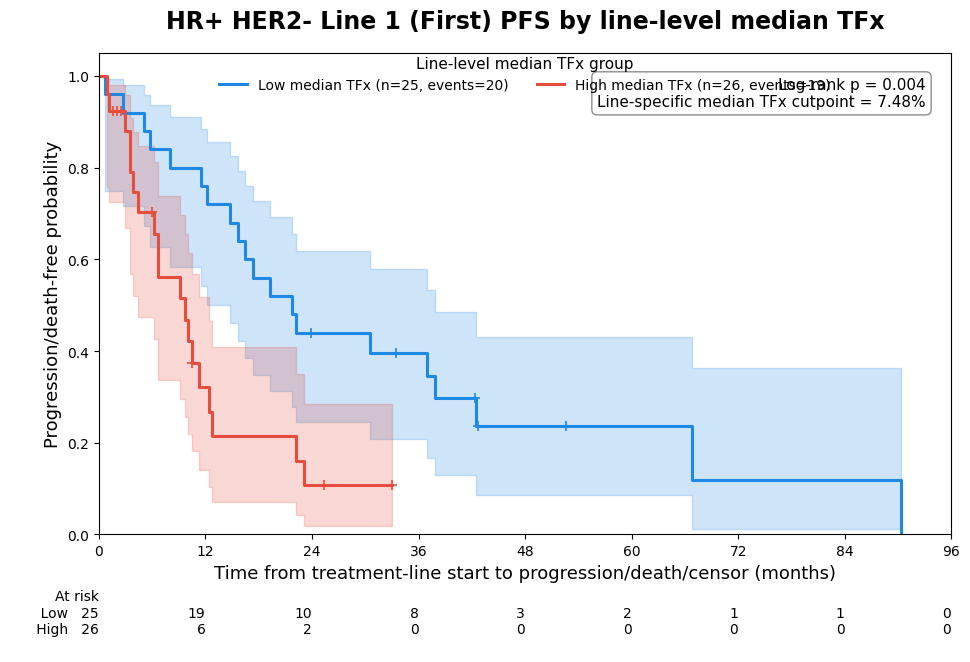

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_01_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_01_python_KM_median_TFx_PFS.pdf

Plotting treatment line 2
Line 2 (Second)
Rows: 34
Events: 25
Censored: 9
TFx cutpoint: 7.589499999999999
Low group: {'n': 17, 'events': 11, 'censored': 6, 'median_TFx': 5.986, 'median_PFS_months_observed': 8.24640657084189}
High group: {'n': 17, 'events': 14, 'censored': 3, 'median_TFx': 22.56, 'median_PFS_months_observed': 6.242299794661191}
Log-rank p-value: 0.29984243877254624


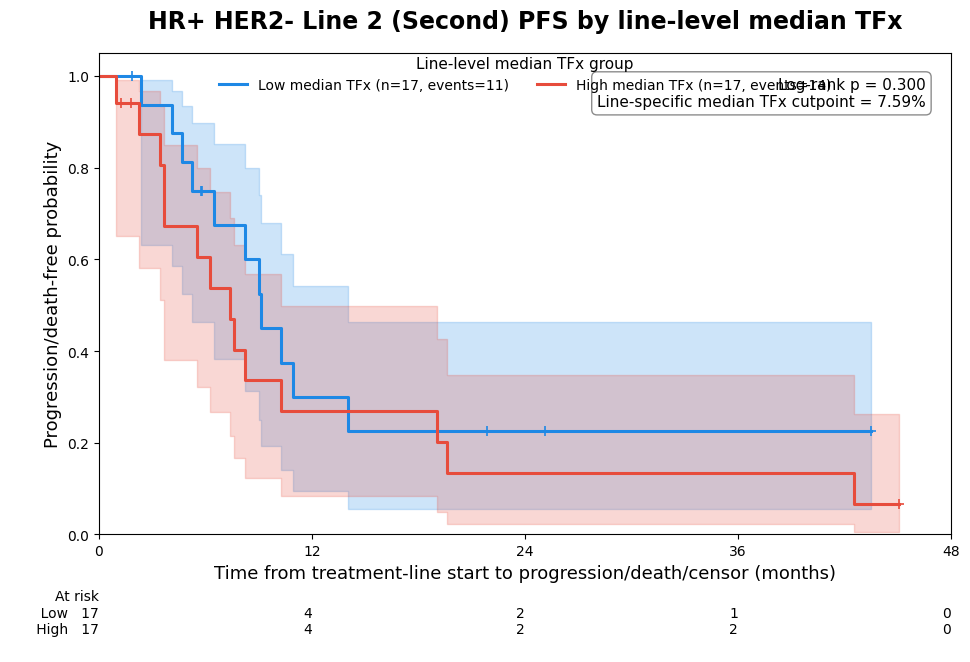

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_02_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_02_python_KM_median_TFx_PFS.pdf

Plotting treatment line 3
Line 3 (Third)
Rows: 28
Events: 24
Censored: 4
TFx cutpoint: 8.0635
Low group: {'n': 14, 'events': 10, 'censored': 4, 'median_TFx': 4.7225, 'median_PFS_months_observed': 6.767967145790554}
High group: {'n': 14, 'events': 14, 'censored': 0, 'median_TFx': 15.50775, 'median_PFS_months_observed': 4.15605749486653}
Log-rank p-value: 0.02608049429164346


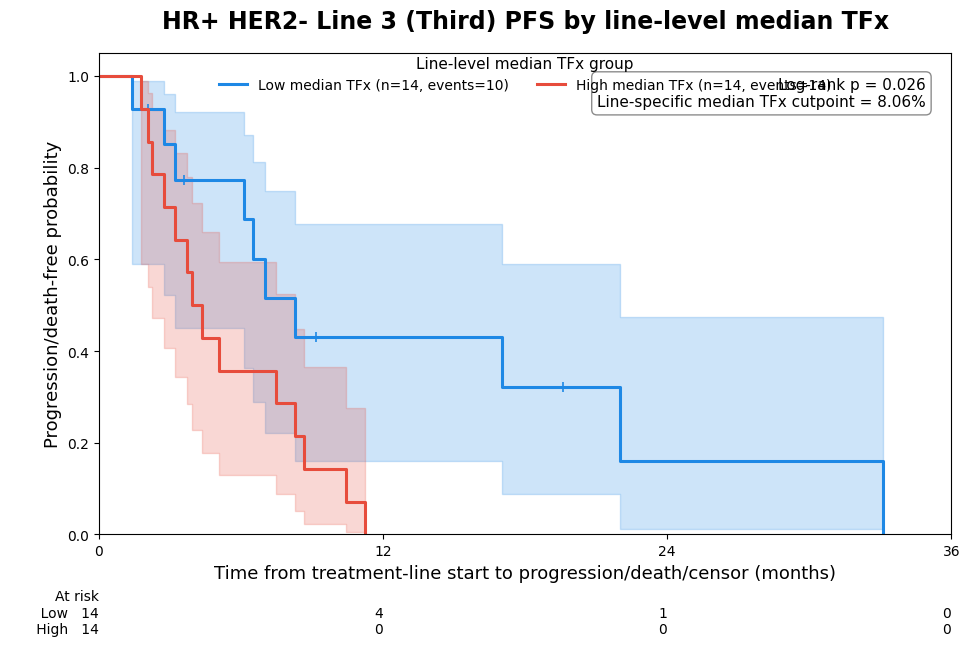

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_03_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_03_python_KM_median_TFx_PFS.pdf

Plotting treatment line 4
Line 4 (Fourth)
Rows: 22
Events: 21
Censored: 1
TFx cutpoint: 8.8695
Low group: {'n': 11, 'events': 10, 'censored': 1, 'median_TFx': 5.016, 'median_PFS_months_observed': 6.078028747433265}
High group: {'n': 11, 'events': 11, 'censored': 0, 'median_TFx': 22.22, 'median_PFS_months_observed': 4.928131416837783}
Log-rank p-value: 0.22365008218310453


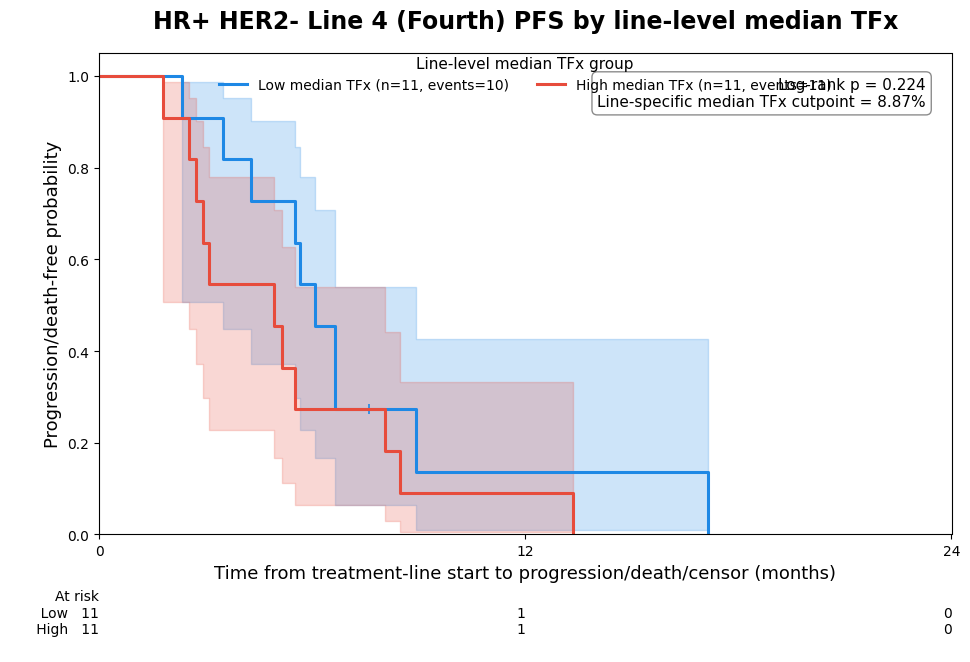

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_04_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_04_python_KM_median_TFx_PFS.pdf

Plotting treatment line 5
Line 5 (Fifth)
Rows: 23
Events: 18
Censored: 5
TFx cutpoint: 6.882000000000001
Low group: {'n': 11, 'events': 8, 'censored': 3, 'median_TFx': 5.545, 'median_PFS_months_observed': 8.279260780287474}
High group: {'n': 12, 'events': 10, 'censored': 2, 'median_TFx': 11.1065, 'median_PFS_months_observed': 4.747433264887064}
Log-rank p-value: 0.2804795952138453


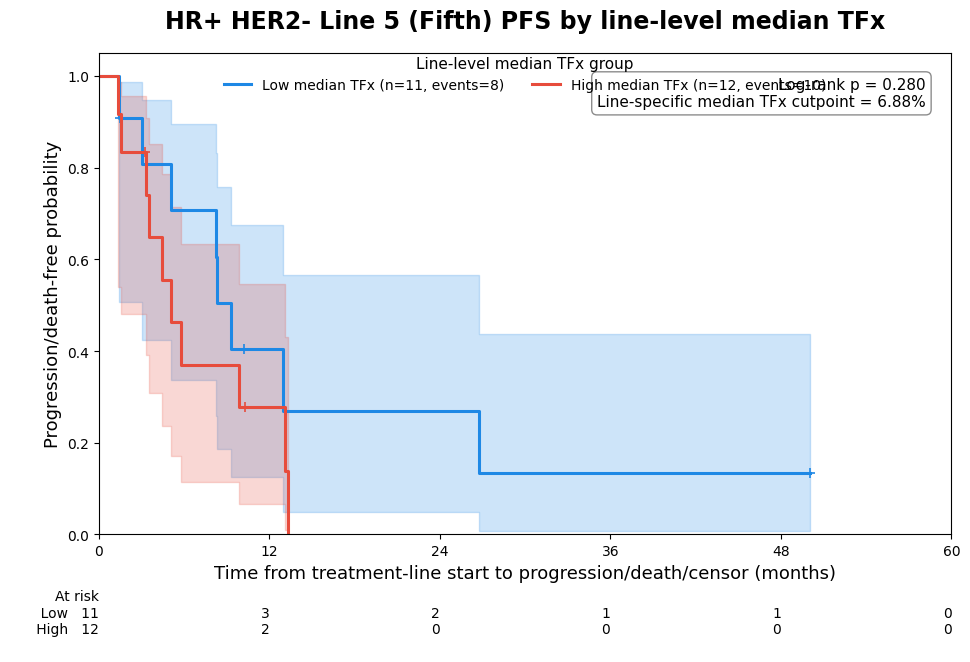

Saved:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_05_python_KM_median_TFx_PFS.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_Line_05_python_KM_median_TFx_PFS.pdf

========== Python KM summary ==========
 treatment_line_number line_label  status  n_patient_lines  n_events  n_censored  line_specific_TFx_cutpoint  low_n  low_events  low_censored  low_median_line_TFx  low_KM_median_PFS_months  high_n  high_events  high_censored  high_median_line_TFx  high_KM_median_PFS_months  logrank_p_value logrank_p_label
                     1      First Plotted               51        39          12                      7.4800     25          20             5               5.1590                 21.749487      26           19              7              14.21900                   9.659138         0.003687     

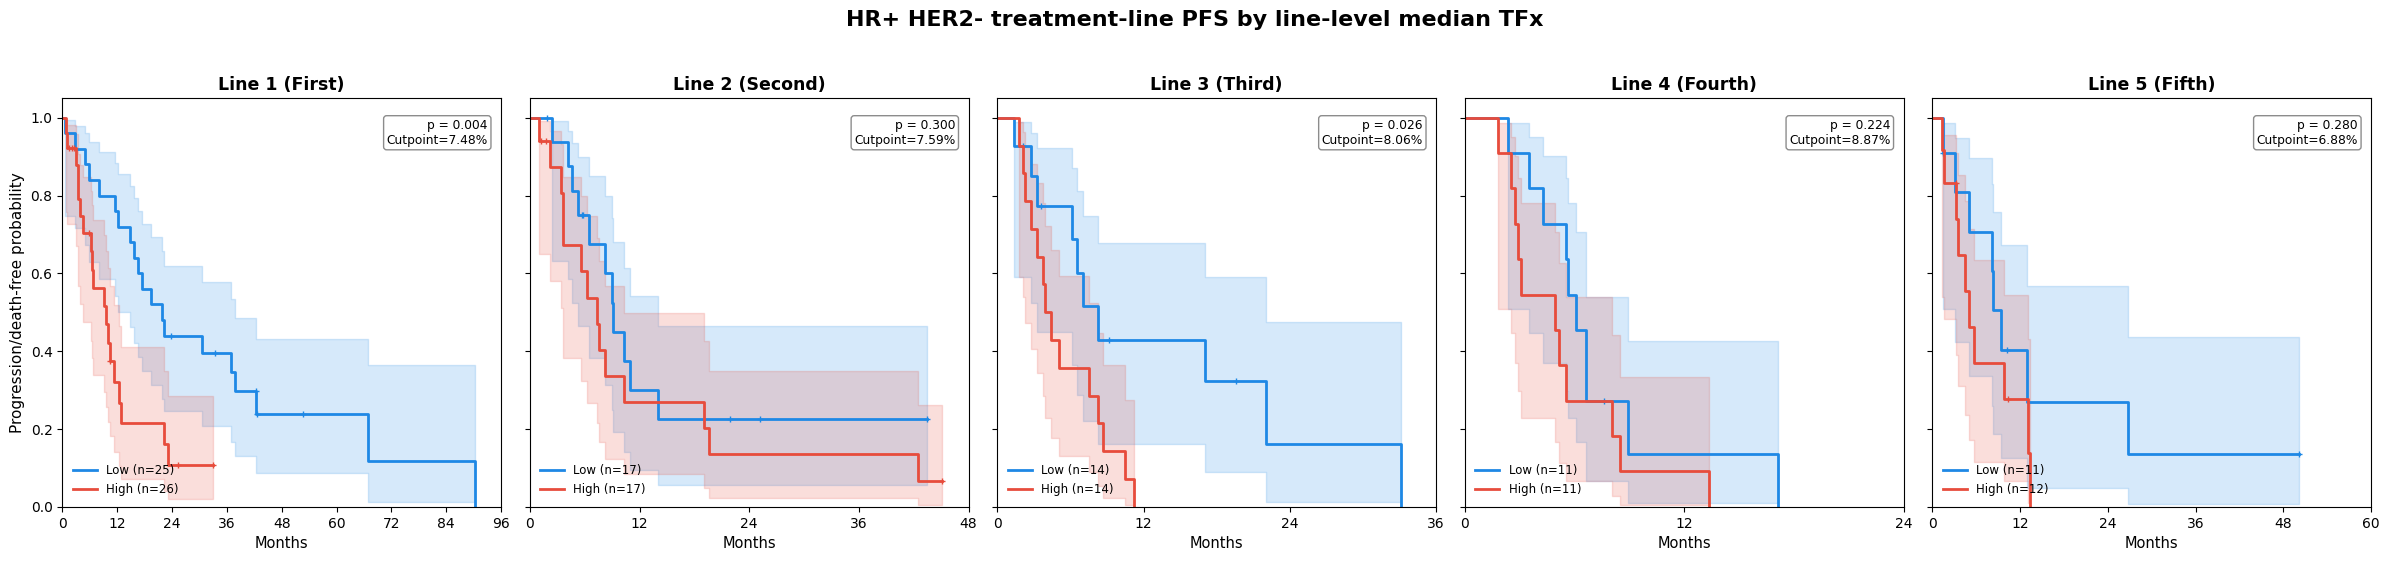


Saved combined preview:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg/Approach2/Python_KM_plots_LINES_1_5/HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.pdf


In [11]:
# ============================================================
# HR+ HER2- treatment-line PFS KM plots (Approach 2)
#
# Input:
#   HRpos_HER2neg_patient_line_median_TFx_PFS_LINES_1_3_for_R.csv
#
# Analysis:
#   - HR+ HER2- only
#   - Blood draws with TFx >= 3% were used upstream
#   - Multiple blood draws within same patient-treatment-line were summarized by median TFx
#   - Within each treatment line, Low/High TFx groups use line-specific median TFx cutpoint
#
# Outputs:
#   - Individual KM plots for Line 1, Line 2, Line 3
#   - Combined 3-panel preview plot
#   - Python KM summary CSV
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# If lifelines is not installed, install/activate it before running:
# !pip install lifelines

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.plotting import add_at_risk_counts


# ============================================================
# 1. Paths
# ============================================================

out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis_HRpos_Herneg"
)

input_file = out_dir / "Approach2" / "HRpos_HER2neg_patient_line_median_TFx_PFS_ALL_LINES.csv"

plot_dir = out_dir / "Approach2" / "Python_KM_plots_LINES_1_5"
plot_dir.mkdir(parents=True, exist_ok=True)

summary_out = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_summary.csv"

print("Input file:")
print(input_file)

print("\nPlot output directory:")
print(plot_dir)


# ============================================================
# 2. Settings
# ============================================================

LINES_TO_PLOT = [1, 2, 3, 4, 5]

time_col = "PFS_time_months"
event_col = "PFS_event"
group_col = "TFx_group_line_median"
line_col = "treatment_line_number"
line_label_col = "line_label"
cut_col = "line_specific_TFx_cutpoint"
tfx_col = "median_TFx_in_line"

low_group = "Low line-level median TFx"
high_group = "High line-level median TFx"

LOW_COLOR = "#1E88E5"
HIGH_COLOR = "#E74C3C"

DPI = 300


# ============================================================
# 3. Helper functions
# ============================================================

def format_p_value(p):
    if pd.isna(p):
        return "p = NA"
    elif p < 0.001:
        return "p < 0.001"
    else:
        return f"p = {p:.3f}"


def format_number(x, digits=2):
    if pd.isna(x):
        return "NA"
    return f"{x:.{digits}f}"


def format_median_survival(x):
    if x is None or pd.isna(x):
        return "NA"
    if np.isinf(x):
        return "Not reached"
    return f"{x:.2f}"


def clean_line_label(line_num, line_label):
    if pd.isna(line_label):
        return f"Line {int(line_num)}"
    return f"Line {int(line_num)} ({line_label})"


def prepare_line_df(df, line_num):
    line_df = df[df[line_col].eq(line_num)].copy()
    
    line_df[time_col] = pd.to_numeric(line_df[time_col], errors="coerce")
    line_df[event_col] = pd.to_numeric(line_df[event_col], errors="coerce")
    line_df[tfx_col] = pd.to_numeric(line_df[tfx_col], errors="coerce")
    
    line_df = line_df[
        line_df[time_col].notna()
        & line_df[event_col].notna()
        & line_df[group_col].notna()
        & (line_df[time_col] > 0)
    ].copy()
    
    line_df[event_col] = line_df[event_col].astype(int)
    
    line_df[group_col] = pd.Categorical(
        line_df[group_col],
        categories=[low_group, high_group],
        ordered=True
    )
    
    return line_df


def get_group_stats(line_df, group_name):
    g = line_df[line_df[group_col].eq(group_name)].copy()
    
    return {
        "n": g.shape[0],
        "events": int(g[event_col].sum()) if g.shape[0] > 0 else 0,
        "censored": int((g[event_col] == 0).sum()) if g.shape[0] > 0 else 0,
        "median_TFx": g[tfx_col].median() if g.shape[0] > 0 else np.nan,
        "median_PFS_months_observed": g[time_col].median() if g.shape[0] > 0 else np.nan,
    }


# ============================================================
# 4. Read data
# ============================================================

df = pd.read_csv(input_file)

print("\n========== Input summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())

# Basic cleanup
df[line_col] = pd.to_numeric(df[line_col], errors="coerce")
df[event_col] = pd.to_numeric(df[event_col], errors="coerce")
df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
df[tfx_col] = pd.to_numeric(df[tfx_col], errors="coerce")

df = df[df[line_col].isin(LINES_TO_PLOT)].copy()
df[line_col] = df[line_col].astype(int)

print("\nTreatment-line counts:")
print(df[line_col].value_counts().sort_index())

print("\nTFx groups by treatment line:")
print(pd.crosstab(df[line_col], df[group_col]))


# ============================================================
# 5. Individual KM plots by treatment line
# ============================================================

summary_rows = []

for line_num in LINES_TO_PLOT:
    
    print("\n============================================================")
    print(f"Plotting treatment line {line_num}")
    print("============================================================")
    
    line_df = prepare_line_df(df, line_num)
    
    if line_df.empty:
        print(f"Skipping Line {line_num}: no valid rows.")
        continue
    
    line_label = line_df[line_label_col].dropna().iloc[0] if line_label_col in line_df.columns and line_df[line_label_col].notna().any() else f"Line {line_num}"
    plot_line_label = clean_line_label(line_num, line_label)
    
    cutpoint = line_df[cut_col].dropna().iloc[0] if cut_col in line_df.columns and line_df[cut_col].notna().any() else line_df[tfx_col].median()
    
    low_df = line_df[line_df[group_col].eq(low_group)].copy()
    high_df = line_df[line_df[group_col].eq(high_group)].copy()
    
    low_stats = get_group_stats(line_df, low_group)
    high_stats = get_group_stats(line_df, high_group)
    
    print(f"{plot_line_label}")
    print("Rows:", line_df.shape[0])
    print("Events:", int(line_df[event_col].sum()))
    print("Censored:", int((line_df[event_col] == 0).sum()))
    print("TFx cutpoint:", cutpoint)
    print("Low group:", low_stats)
    print("High group:", high_stats)
    
    if low_df.shape[0] == 0 or high_df.shape[0] == 0:
        print(f"Skipping Line {line_num}: one TFx group is missing.")
        continue
    
    # ----------------------------
    # Fit KM curves
    # ----------------------------
    low_label = f"Low median TFx (n={low_stats['n']}, events={low_stats['events']})"
    high_label = f"High median TFx (n={high_stats['n']}, events={high_stats['events']})"
    
    kmf_low = KaplanMeierFitter(label=low_label)
    kmf_high = KaplanMeierFitter(label=high_label)
    
    kmf_low.fit(
        durations=low_df[time_col],
        event_observed=low_df[event_col]
    )
    
    kmf_high.fit(
        durations=high_df[time_col],
        event_observed=high_df[event_col]
    )
    
    # ----------------------------
    # Log-rank test
    # ----------------------------
    lr = logrank_test(
        low_df[time_col],
        high_df[time_col],
        event_observed_A=low_df[event_col],
        event_observed_B=high_df[event_col]
    )
    
    p_val = lr.p_value
    p_label = format_p_value(p_val)
    
    print("Log-rank p-value:", p_val)
    
    # ----------------------------
    # Plot settings
    # ----------------------------
    max_time = line_df[time_col].max()
    x_max = int(np.ceil(max_time / 12) * 12)
    x_max = max(x_max, 12)
    
    x_ticks = np.arange(0, x_max + 1, 12)
    
    annot_text = (
        f"Log-rank {p_label}\n"
        f"Line-specific median TFx cutpoint = {cutpoint:.2f}%"
    )
    
    # ----------------------------
    # Plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=(11, 8.3))
    
    kmf_low.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.22,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 7, "mew": 1.2},
        color=LOW_COLOR,
        linewidth=2.2
    )
    
    kmf_high.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.22,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 7, "mew": 1.2},
        color=HIGH_COLOR,
        linewidth=2.2
    )
    
    ax.set_title(
        f"HR+ HER2- {plot_line_label} PFS by line-level median TFx",
        fontsize=17,
        fontweight="bold",
        pad=18
    )
    
    ax.set_xlabel(
        "Time from treatment-line start to progression/death/censor (months)",
        fontsize=13
    )
    
    ax.set_ylabel(
        "Progression/death-free probability",
        fontsize=13
    )
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(x_ticks)
    
    ax.grid(False)
    
    ax.legend(
        title="Line-level median TFx group",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        frameon=False,
        fontsize=10,
        title_fontsize=11
    )
    
    ax.text(
        0.97,
        0.95,
        annot_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )
    
    # Single number-at-risk table only
    add_at_risk_counts(
        kmf_low,
        kmf_high,
        ax=ax,
        labels=["Low", "High"],
        rows_to_show=["At risk"],
        fontsize=10
    )
    
    plt.subplots_adjust(bottom=0.26, top=0.84)
    
    out_png = plot_dir / f"HRpos_HER2neg_Line_{line_num:02d}_python_KM_median_TFx_PFS.png"
    out_pdf = plot_dir / f"HRpos_HER2neg_Line_{line_num:02d}_python_KM_median_TFx_PFS.pdf"
    
    fig.savefig(out_png, dpi=DPI, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    
    plt.show()
    plt.close(fig)
    
    print("Saved:")
    print(out_png)
    print(out_pdf)
    
    # ----------------------------
    # Store summary
    # ----------------------------
    summary_rows.append(
        {
            "treatment_line_number": line_num,
            "line_label": line_label,
            "status": "Plotted",
            "n_patient_lines": line_df.shape[0],
            "n_events": int(line_df[event_col].sum()),
            "n_censored": int((line_df[event_col] == 0).sum()),
            "line_specific_TFx_cutpoint": cutpoint,
            
            "low_n": low_stats["n"],
            "low_events": low_stats["events"],
            "low_censored": low_stats["censored"],
            "low_median_line_TFx": low_stats["median_TFx"],
            "low_KM_median_PFS_months": kmf_low.median_survival_time_,
            
            "high_n": high_stats["n"],
            "high_events": high_stats["events"],
            "high_censored": high_stats["censored"],
            "high_median_line_TFx": high_stats["median_TFx"],
            "high_KM_median_PFS_months": kmf_high.median_survival_time_,
            
            "logrank_p_value": p_val,
            "logrank_p_label": p_label,
        }
    )


# ============================================================
# 6. Save KM summary
# ============================================================

km_summary = pd.DataFrame(summary_rows)

km_summary.to_csv(summary_out, index=False)

print("\n========== Python KM summary ==========")
print(km_summary.to_string(index=False))

print("\nSaved summary:")
print(summary_out)


# ============================================================
# 7. Combined 5-panel preview plot
#    Curve-only preview, no risk table
# ============================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(LINES_TO_PLOT),
    figsize=(24, 5.4),
    sharey=True
)

for ax, line_num in zip(axes, LINES_TO_PLOT):
    
    line_df = prepare_line_df(df, line_num)
    
    if line_df.empty:
        ax.set_title(f"Line {line_num}: no data")
        ax.axis("off")
        continue
    
    line_label = (
        line_df[line_label_col].dropna().iloc[0]
        if line_label_col in line_df.columns and line_df[line_label_col].notna().any()
        else f"Line {line_num}"
    )
    
    plot_line_label = clean_line_label(line_num, line_label)
    
    cutpoint = (
        line_df[cut_col].dropna().iloc[0]
        if cut_col in line_df.columns and line_df[cut_col].notna().any()
        else line_df[tfx_col].median()
    )
    
    low_df = line_df[line_df[group_col].eq(low_group)].copy()
    high_df = line_df[line_df[group_col].eq(high_group)].copy()
    
    low_stats = get_group_stats(line_df, low_group)
    high_stats = get_group_stats(line_df, high_group)
    
    if low_df.shape[0] == 0 or high_df.shape[0] == 0:
        ax.set_title(f"{plot_line_label}: missing group")
        ax.axis("off")
        continue
    
    kmf_low = KaplanMeierFitter(label=f"Low (n={low_stats['n']})")
    kmf_high = KaplanMeierFitter(label=f"High (n={high_stats['n']})")
    
    kmf_low.fit(
        low_df[time_col],
        event_observed=low_df[event_col]
    )
    
    kmf_high.fit(
        high_df[time_col],
        event_observed=high_df[event_col]
    )
    
    lr = logrank_test(
        low_df[time_col],
        high_df[time_col],
        event_observed_A=low_df[event_col],
        event_observed_B=high_df[event_col]
    )
    
    p_label = format_p_value(lr.p_value)
    
    kmf_low.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.18,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 5},
        color=LOW_COLOR,
        linewidth=2
    )
    
    kmf_high.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.18,
        show_censors=True,
        censor_styles={"marker": "+", "ms": 5},
        color=HIGH_COLOR,
        linewidth=2
    )
    
    max_time = line_df[time_col].max()
    x_max = int(np.ceil(max_time / 12) * 12)
    x_max = max(x_max, 12)
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(np.arange(0, x_max + 1, 12))
    
    ax.set_title(
        plot_line_label,
        fontsize=12.5,
        fontweight="bold"
    )
    
    ax.set_xlabel("Months", fontsize=10.5)
    
    if line_num == LINES_TO_PLOT[0]:
        ax.set_ylabel("Progression/death-free probability", fontsize=11)
    else:
        ax.set_ylabel("")
    
    ax.grid(False)
    
    ax.text(
        0.97,
        0.95,
        f"{p_label}\nCutpoint={cutpoint:.2f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.8,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )
    
    ax.legend(
        loc="lower left",
        frameon=False,
        fontsize=8.5
    )

fig.suptitle(
    "HR+ HER2- treatment-line PFS by line-level median TFx",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

combined_png = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.png"
combined_pdf = plot_dir / "HRpos_HER2neg_LINES_1_5_python_KM_combined_preview.pdf"

fig.savefig(combined_png, dpi=DPI, bbox_inches="tight")
fig.savefig(combined_pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nSaved combined preview:")
print(combined_png)
print(combined_pdf)